# Bài thực hành khai phá dữ liệu — Dự đoán giá & phân cụm chuỗi giá rau quả Việt Nam

**Học phần:** INT1422 · Kho dữ liệu và Khai phá dữ liệu — làm theo cấu trúc *Đề 01 (California Housing)*,
áp dụng trên dữ liệu thật do nhóm tự thu thập.

**Dữ liệu:** giá rau quả trong nước do cộng tác viên địa phương báo về cổng *thitruongnongsan.gov.vn*
(mục "Giá rau quả trong nước"), 04/2021 → 12/2025. Dữ liệu được thu thập và làm sạch bởi luồng ETL của nhóm
(Airflow → MinIO → ClickHouse) và đọc từ **kho dữ liệu** (view `ttns.v_price_monthly`) — tức là khai phá trên kho
(OLAM, Bài 6) chứ không phải trên file thô.

**Hai nhiệm vụ** (tương ứng Đề 01)
1. **Học có giám sát:** dự đoán giá trung vị tháng (VNĐ/kg) của một mặt hàng tại một tỉnh, theo một loại giá.
2. **Học không giám sát:** phân cụm các chuỗi giá theo *hành vi* (mùa vụ, biến động, xu hướng) để tìm các nhóm
   mặt hàng có cùng nhịp giá; dùng DBSCAN để tìm các chuỗi có hành vi dị biệt.

| Đề 01 (California) | Bài này (giá rau quả) |
|---|---|
| 1 khu dân cư | 1 bản ghi = mặt hàng × tỉnh × loại giá × tháng |
| `median_house_value` | `median_price` — giá trung vị trong tháng (VNĐ/kg) |
| `ocean_proximity` | `cap_gia` (Bán lẻ / Bán buôn / Thu mua) và vùng miền |
| số phòng trên mỗi hộ… | giá tháng trước, giá cùng kỳ năm trước, trung bình 3 lần báo giá gần nhất… |
| K-Means trên đặc trưng kinh tế – xã hội (không dùng giá nhà) | K-Means trên hành vi giá của chuỗi (không dùng mức giá) |
| DBSCAN trên toạ độ địa lý | DBSCAN trên hành vi giá → chuỗi dị biệt (chỉ có 15 tỉnh nên DBSCAN theo toạ độ không có ý nghĩa) |

*Khai báo sử dụng công cụ AI theo yêu cầu Bài 12: notebook được soạn với sự hỗ trợ của Claude (Anthropic).*

In [1]:
import os
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.cluster import DBSCAN, KMeans
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.decomposition import PCA
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, silhouette_samples,
                             silhouette_score)
from sklearn.model_selection import GridSearchCV, cross_validate
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
RANDOM_STATE = 42
FIG = Path("figures/dt01")
FIG.mkdir(parents=True, exist_ok=True)

# Giao diện biểu đồ: bảng màu tham chiếu (đã kiểm tra mù màu), nền sáng để in báo cáo
SURF, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
S1, S2, S3, S4 = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
CAP_COLOR = {"Bán lẻ": S1, "Thu mua": S2, "Bán buôn": S3}
SEQ = LinearSegmentedColormap.from_list("blue", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("div", ["#184f95", "#5598e7", "#f0efec", "#e66767", "#a32626"])
plt.rcParams.update({
    "font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 10, "figure.facecolor": SURF, "axes.facecolor": SURF,
    "savefig.facecolor": SURF, "axes.edgecolor": AXIS, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True, "xtick.color": MUTED,
    "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2, "axes.labelcolor": INK2,
    "axes.titlesize": 12.5, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 10,
    "lines.linewidth": 2, "legend.frameon": False, "figure.dpi": 100, "savefig.dpi": 200, "savefig.bbox": "tight",
})


PLAIN = plt.FuncFormatter(lambda v, _: f"{v:g}")                         # trục log hiện 5, 10, 20… thay vì 10^1


def plain_log_x(ax):
    ax.xaxis.set_major_formatter(PLAIN)
    ax.xaxis.set_minor_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}" if str(v)[0] in "25" else ""))


def show(fig, name):
    fig.savefig(FIG / f"{name}.png")
    plt.show()

## 0. Đọc dữ liệu từ kho
Truy vấn view `ttns.v_price_monthly` trong ClickHouse (bảng sự kiện `fact_price_monthly` đã nối 3 bảng chiều
Sản phẩm, Địa điểm, Thời gian). Nếu ClickHouse không chạy, đọc bản chụp `data/ttns_v_price_monthly.csv`
(được xuất từ chính view này) để notebook luôn chạy lại được.

In [2]:
SQL = """
SELECT month, year, quarter, month_no, nhom_san_pham, san_pham, mat_hang, tinh_cu, tinh_moi,
       loai_gia, cap_gia, don_vi_tinh, median_price, avg_price, min_price, max_price, n_obs, n_outliers
FROM ttns.v_price_monthly
ORDER BY month
FORMAT CSVWithNames
"""
SNAPSHOT = Path("data/ttns_v_price_monthly.csv")
try:
    r = requests.post(os.getenv("CLICKHOUSE_URL", "http://localhost:8123"), data=SQL.encode("utf-8"),
                      auth=("default", os.getenv("CLICKHOUSE_PASSWORD", "mypassword")), timeout=30)
    r.raise_for_status()
    from io import StringIO
    raw = pd.read_csv(StringIO(r.text), parse_dates=["month"])
    source = "ClickHouse (ttns.v_price_monthly)"
except Exception as exc:  # kho không chạy -> dùng bản chụp
    raw = pd.read_csv(SNAPSHOT, parse_dates=["month"])
    source = f"bản chụp {SNAPSHOT} ({type(exc).__name__})"
print(f"Nguồn: {source} — {len(raw):,} dòng × {raw.shape[1]} cột")
raw.head()

Nguồn: ClickHouse (ttns.v_price_monthly) — 7,337 dòng × 18 cột


,month,year,quarter,month_no,nhom_san_pham,san_pham,mat_hang,tinh_cu,tinh_moi,loai_gia,cap_gia,don_vi_tinh,median_price,avg_price,min_price,max_price,n_obs,n_outliers
0,2021-04-01,2021,2,4,Trái cây,Xoài,Xoài Đài Loan,Đồng Tháp,Đồng Tháp,Thu mua,Thu mua,VNĐ/kg,15000,"15,000.000",15000,15000,1,0
1,2021-04-01,2021,2,4,Trái cây,Xoài,Xoài Đài Loan,Sơn La,Sơn La,Bán lẻ,Bán lẻ,VNĐ/kg,30000,"30,000.000",30000,30000,8,0
2,2021-04-01,2021,2,4,Trái cây,Xoài,Xoài Đài Loan,An Giang,An Giang,Thu mua,Thu mua,VNĐ/kg,8000,"8,000.000",8000,8000,1,0
3,2021-04-01,2021,2,4,Trái cây,Sầu riêng,Sầu riêng KQX,Vĩnh Long,Vĩnh Long,Bán buôn,Bán buôn,VNĐ/kg,16000,"16,000.000",16000,16000,1,0
4,2021-04-01,2021,2,4,Trái cây,Cam,Cam dây,Tiền Giang,Đồng Tháp,Thu mua,Thu mua,VNĐ/kg,10000,"10,000.000",9500,10500,2,0


## 1. Khám phá dữ liệu (EDA)
### 1.1 Tổng quan: kiểu dữ liệu, thống kê mô tả, giá trị thiếu, biến phân loại

In [3]:
info = pd.DataFrame({
    "kiểu": raw.dtypes.astype(str),
    "số giá trị khác nhau": raw.nunique(),
    "số ô thiếu": raw.isna().sum(),
    "% thiếu": raw.isna().mean() * 100,
    "ví dụ": raw.iloc[0],
})
info

,kiểu,số giá trị khác nhau,số ô thiếu,% thiếu,ví dụ
month,datetime64[ns],57,0,0.000,2021-04-01 00:00:00
year,int64,5,0,0.000,2021
quarter,int64,4,0,0.000,2
month_no,int64,12,0,0.000,4
nhom_san_pham,object,2,0,0.000,Trái cây
san_pham,object,73,0,0.000,Xoài
mat_hang,object,195,0,0.000,Xoài Đài Loan
tinh_cu,object,15,0,0.000,Đồng Tháp
tinh_moi,object,9,0,0.000,Đồng Tháp
loai_gia,object,7,0,0.000,Thu mua


In [4]:
raw.describe().T

,count,mean,min,25%,50%,75%,max,std
month,7337,2023-11-19 04:24:22.178001920,2021-04-01 00:00:00,2022-09-01 00:00:00,2024-03-01 00:00:00,2025-02-01 00:00:00,2025-12-01 00:00:00,NaN
year,"7,337.000","2,023.389","2,021.000","2,022.000","2,024.000","2,025.000","2,025.000",1.403
quarter,"7,337.000",2.642,1.000,2.000,3.000,4.000,4.000,1.072
month_no,"7,337.000",6.933,1.000,4.000,7.000,10.000,12.000,3.330
median_price,"7,337.000","26,811.574","1,000.000","12,500.000","20,000.000","35,000.000","350,000.000","23,313.920"
avg_price,"7,337.000","26,848.391","1,000.000","12,923.100","20,000.000","33,750.000","350,000.000","23,247.862"
min_price,"7,337.000","24,901.797","1,000.000","12,000.000","18,500.000","30,000.000","350,000.000","22,043.357"
max_price,"7,337.000","28,884.951","1,000.000","14,500.000","22,000.000","35,000.000","350,000.000","24,803.459"
n_obs,"7,337.000",5.515,1.000,4.000,4.000,8.000,285.000,5.635
n_outliers,"7,337.000",0.009,0.000,0.000,0.000,0.000,6.000,0.148


In [5]:
for col in ["don_vi_tinh", "cap_gia", "loai_gia", "nhom_san_pham", "tinh_moi"]:
    vc = raw[col].value_counts()
    print(f"\n{col}: {len(vc)} giá trị\n" + ", ".join(f"{k}: {v}" for k, v in vc.items()))


don_vi_tinh: 6 giá trị
VNĐ/kg: 6925, VNĐ/chục quả: 177, VNĐ/mớ: 128, VNĐ/quả: 87, VNĐ/củ: 17, VNĐ/cây: 3

cap_gia: 3 giá trị
Thu mua: 3591, Bán lẻ: 3321, Bán buôn: 425

loai_gia: 7 giá trị
Thu mua: 3424, Bán lẻ: 3265, Bán buôn: 413, Thương lái thu mua: 123, Tại chợ: 56, Tại vườn: 44, Tại vựa: 12

nhom_san_pham: 2 giá trị
Trái cây: 5152, Rau củ quả: 2185

tinh_moi: 9 giá trị
Đồng Tháp: 1630, Sơn La: 1606, TP. Hà Nội: 1308, TP. Cần Thơ: 1240, Vĩnh Long: 1074, Cà Mau: 291, Tây Ninh: 88, An Giang: 86, Hưng Yên: 14


**Nhận xét tổng quan**
- Bảng không có ô thiếu: các giá trị thiếu ở nguồn (33 dòng thiếu tỉnh mới) đã được xử lý ở bước ETL.
  **Thiếu dữ liệu thật sự nằm ở dạng tháng trống**: một chuỗi giá không có báo giá ở một số tháng (xem 1.2).
- **95% bản ghi dùng đơn vị VNĐ/kg.** Các đơn vị khác (chục quả, mớ, quả, củ, cây) không so sánh được với /kg →
  chỉ giữ VNĐ/kg cho mô hình (bỏ 412 dòng, ~6%).
- **Nhóm có quá ít mẫu:** loại giá "Tại vựa" (12), "Tại vườn" (44), "Tại chợ" (56) → dùng `cap_gia` (3 cấp đã gộp
  ở ETL) thay cho `loai_gia`; tỉnh Thái Bình / Kiên Giang / Trà Vinh chỉ ~30 dòng mỗi tỉnh.

In [6]:
df = raw[raw["don_vi_tinh"] == "VNĐ/kg"].copy()
KEY = ["nhom_san_pham", "san_pham", "mat_hang", "tinh_cu", "loai_gia"]  # 1 chuỗi giá
df["sid"] = df.groupby(KEY, sort=True).ngroup()
VUNG = {"Sơn La": "Trung du & miền núi phía Bắc", "Hà Nội": "Đồng bằng sông Hồng", "Thái Bình": "Đồng bằng sông Hồng"}
df["vung"] = df["tinh_cu"].map(VUNG).fillna("Đồng bằng sông Cửu Long")   # 12 tỉnh còn lại đều thuộc ĐBSCL
df = df.sort_values(["sid", "month"]).reset_index(drop=True)

span = df.groupby("sid")["month"].agg(["min", "max", "count"])
span["so_thang_ky_vong"] = ((span["max"].dt.year - span["min"].dt.year) * 12 + span["max"].dt.month - span["min"].dt.month + 1)
missing_months = 1 - span["count"].sum() / span["so_thang_ky_vong"].sum()
print(f"VNĐ/kg: {len(df):,} bản ghi, {df['sid'].nunique()} chuỗi giá, {df['san_pham'].nunique()} sản phẩm, "
      f"{df['tinh_cu'].nunique()} tỉnh")
print(f"Tháng trống trong khoảng hoạt động của các chuỗi: {missing_months:.1%}")
print(f"Độ dài chuỗi: trung bình {span['count'].mean():.1f} tháng; ≥ 24 tháng: {(span['count'] >= 24).sum()} chuỗi")

VNĐ/kg: 6,925 bản ghi, 429 chuỗi giá, 73 sản phẩm, 14 tỉnh
Tháng trống trong khoảng hoạt động của các chuỗi: 31.9%
Độ dài chuỗi: trung bình 16.1 tháng; ≥ 24 tháng: 126 chuỗi


### 1.2 Phân phối biến mục tiêu và các điểm bất thường

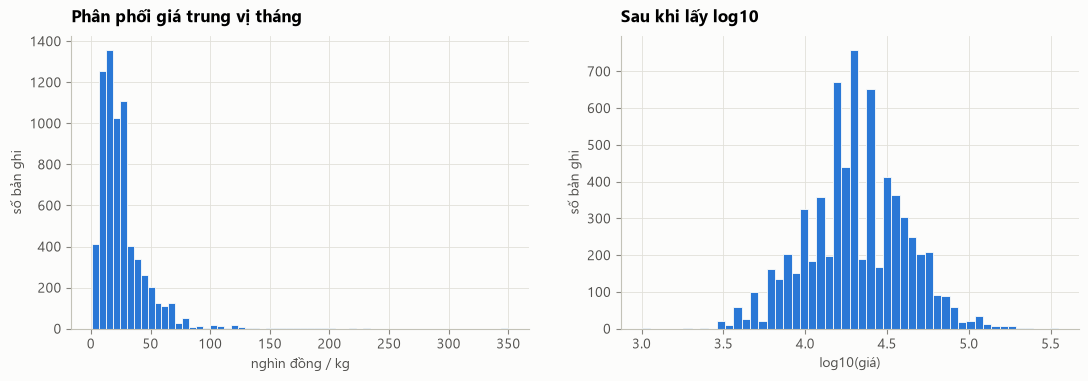

Độ lệch (skewness): giá = 3.27; log(giá) = -0.01
Trung bình 25,798 > trung vị 20,000 → lệch dương (đuôi dài bên phải)


In [7]:
y_all = df["median_price"]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].hist(y_all / 1000, bins=60, color=S1, edgecolor=SURF, linewidth=0.6)
axes[0].set_title("Phân phối giá trung vị tháng")
axes[0].set_xlabel("nghìn đồng / kg")
axes[1].hist(np.log10(y_all), bins=50, color=S1, edgecolor=SURF, linewidth=0.6)
axes[1].set_title("Sau khi lấy log10")
axes[1].set_xlabel("log10(giá)")
for ax in axes:
    ax.set_ylabel("số bản ghi")
show(fig, "01_phan_phoi_gia")
print(f"Độ lệch (skewness): giá = {y_all.skew():.2f}; log(giá) = {np.log(y_all).skew():.2f}")
print(f"Trung bình {y_all.mean():,.0f} > trung vị {y_all.median():,.0f} → lệch dương (đuôi dài bên phải)")

In [8]:
# Ngoại lai theo quy tắc IQR (Bài 6, Bài 13) trên log giá
q1, q3 = np.log(y_all).quantile([0.25, 0.75])
lo, hi = np.exp(q1 - 1.5 * (q3 - q1)), np.exp(q3 + 1.5 * (q3 - q1))
out = df[(y_all < lo) | (y_all > hi)]
print(f"Cận IQR trên log giá: {lo:,.0f} → {hi:,.0f} VNĐ/kg; {len(out)} bản ghi ngoài cận ({len(out) / len(df):.1%})")
display(out.groupby(["san_pham", "cap_gia"]).agg(so_ban_ghi=("median_price", "size"),
                                                 gia_trung_vi=("median_price", "median"))
        .sort_values("so_ban_ghi", ascending=False).head(10))

Cận IQR trên log giá: 3,366 → 123,583 VNĐ/kg; 71 bản ghi ngoài cận (1.0%)


,,so_ban_ghi,gia_trung_vi
san_pham,cap_gia,,
Hạt ca cao,Thu mua,18,"170,000.000"
Chuối,Thu mua,12,"3,000.000"
Sầu riêng,Thu mua,11,"127,500.000"
Cóc Thái,Thu mua,7,"2,000.000"
Dâu,Bán lẻ,6,"190,000.000"
Cam,Thu mua,5,"3,000.000"
Ổi,Thu mua,4,"3,125.000"
Trái Cóc mỡ,Thu mua,3,"3,000.000"
Mận,Bán lẻ,2,"177,500.000"


In [9]:
# Giá trị bị "làm tròn / dồn cục" (tương tự giá nhà bị chặn trên ở Đề 01): cộng tác viên hay báo số tròn
round_share = (y_all % 5000 == 0).mean()
top_vals = y_all.value_counts().head(8)
print(f"{round_share:.0%} giá là bội số của 5.000đ; các giá hay gặp nhất:")
print(", ".join(f"{v:,.0f}đ ({c} lần)" for v, c in top_vals.items()))

52% giá là bội số của 5.000đ; các giá hay gặp nhất:
20,000đ (587 lần), 25,000đ (535 lần), 15,000đ (500 lần), 30,000đ (326 lần), 35,000đ (297 lần), 10,000đ (268 lần), 40,000đ (252 lần), 18,000đ (219 lần)


**Điểm bất thường phát hiện được**
- **Lệch dương mạnh:** vài sản phẩm đắt (hạt ca cao, dâu tây, măng tây, sầu riêng) kéo đuôi phải → dùng **log(giá)**
  làm biến mục tiêu khi huấn luyện; đánh giá lại trên VNĐ.
- **Ngoại lai theo IQR** phần lớn là *giá thật của sản phẩm đắt*, không phải lỗi → **giữ lại** (giá nhập sai
  lệch > 5 lần trung vị đã bị loại ở bước ETL, cột `n_outliers`).
- **Giá dồn cục ở số tròn** (bội số 5.000đ) và nhiều tháng giá đứng yên → mô hình sẽ khó dự đoán các thay đổi nhỏ.

### 1.3 Quan hệ giữa các đặc trưng và giá

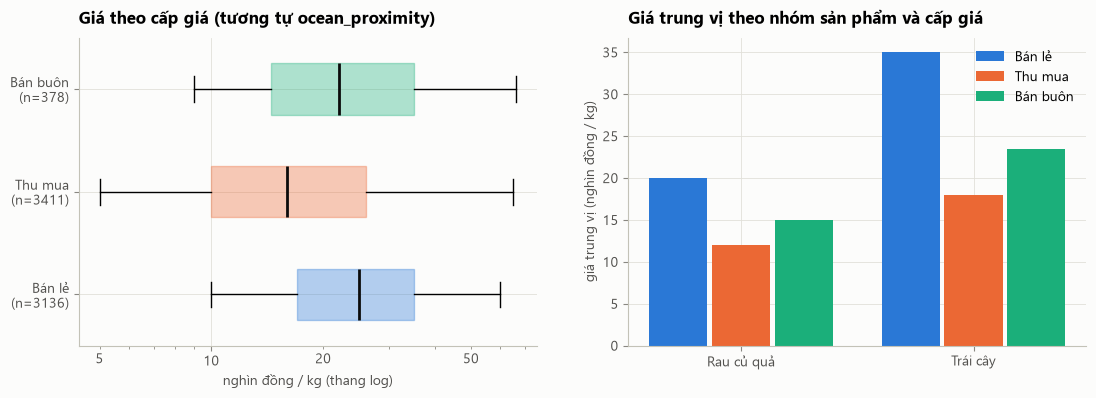

,count,25%,50%,75%
cap_gia,,,,
Bán buôn,378.000,"14,500.000","22,000.000","35,000.000"
Bán lẻ,"3,136.000","17,000.000","25,000.000","35,000.000"
Thu mua,"3,411.000","10,000.000","16,000.000","26,000.000"


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
caps = list(CAP_COLOR)
data = [df.loc[df["cap_gia"] == c, "median_price"] / 1000 for c in caps]
bp = axes[0].boxplot(data, vert=False, tick_labels=[f"{c}\n(n={len(d)})" for c, d in zip(caps, data)], whis=(5, 95),
                     showfliers=False, patch_artist=True, widths=0.5, medianprops=dict(color=INK, linewidth=2))
for p, c in zip(bp["boxes"], caps):
    p.set(facecolor=CAP_COLOR[c], alpha=0.35, edgecolor=CAP_COLOR[c])
axes[0].set_xscale("log")
plain_log_x(axes[0])
axes[0].set_title("Giá theo cấp giá (tương tự ocean_proximity)")
axes[0].set_xlabel("nghìn đồng / kg (thang log)")
nh = df.groupby(["nhom_san_pham", "cap_gia"])["median_price"].median().unstack()[caps] / 1000
x = np.arange(len(nh))
for i, c in enumerate(caps):
    axes[1].bar(x + (i - 1) * 0.27, nh[c], width=0.25, color=CAP_COLOR[c], label=c)
axes[1].set_xticks(x, nh.index)
axes[1].set_ylabel("giá trung vị (nghìn đồng / kg)")
axes[1].set_title("Giá trung vị theo nhóm sản phẩm và cấp giá")
axes[1].legend()
show(fig, "02_gia_theo_cap_gia")
display(df.groupby("cap_gia")["median_price"].describe()[["count", "25%", "50%", "75%"]])

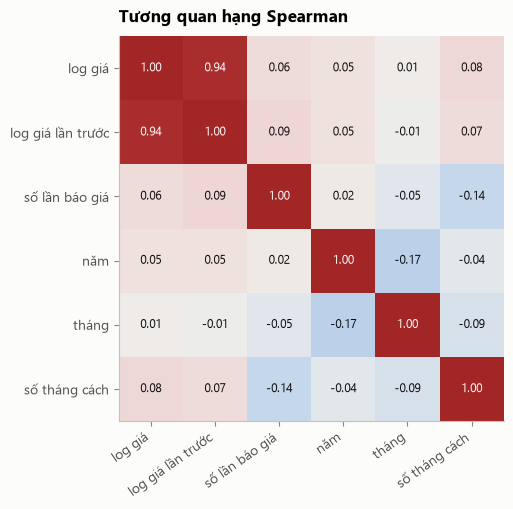

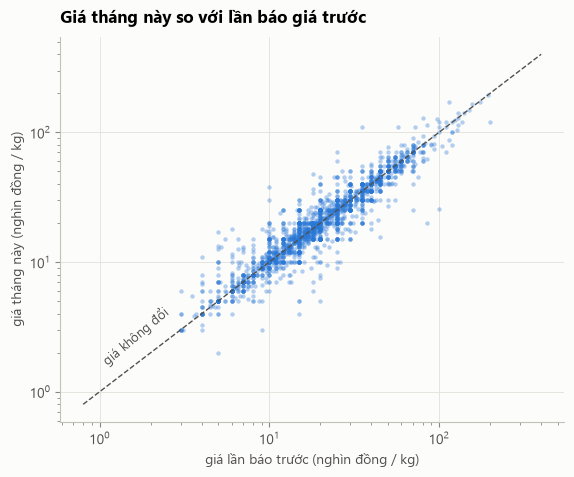

In [11]:
# Đặc trưng thời gian và quá khứ -> tương quan với giá (dùng log vì giá lệch)
tmp = df[["sid", "month", "median_price", "n_obs", "year", "month_no"]].copy()
tmp["log_gia"] = np.log(tmp["median_price"])
prev = tmp.groupby("sid")[["month", "log_gia"]].shift(1)
tmp["log_gia_lan_truoc"] = prev["log_gia"]
tmp["so_thang_cach"] = (tmp["month"].dt.year - prev["month"].dt.year) * 12 + tmp["month"].dt.month - prev["month"].dt.month
corr = tmp[["log_gia", "log_gia_lan_truoc", "n_obs", "year", "month_no", "so_thang_cach"]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(6.5, 5))
im = ax.imshow(corr.values, cmap=DIV, vmin=-1, vmax=1)
ax.grid(False)
lab = ["log giá", "log giá lần trước", "số lần báo giá", "năm", "tháng", "số tháng cách"]
ax.set_xticks(range(len(lab)), lab, rotation=35, ha="right")
ax.set_yticks(range(len(lab)), lab)
for i in range(len(lab)):
    for j in range(len(lab)):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=8.5,
                color="white" if abs(corr.values[i, j]) > 0.6 else INK)
ax.set_title("Tương quan hạng Spearman")
show(fig, "03_tuong_quan")

fig, ax = plt.subplots(figsize=(6.5, 5))
s = tmp.dropna(subset=["log_gia_lan_truoc"]).sample(2500, random_state=RANDOM_STATE)
ax.scatter(np.exp(s["log_gia_lan_truoc"]) / 1000, s["median_price"] / 1000, s=10, alpha=0.35, color=S1, linewidth=0)
lim = [0.8, 400]
ax.plot(lim, lim, color=INK2, linestyle="--", linewidth=1)
ax.text(1.0, 1.6, "giá không đổi", color=INK2, fontsize=9, rotation=40)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("giá lần báo trước (nghìn đồng / kg)")
ax.set_ylabel("giá tháng này (nghìn đồng / kg)")
ax.set_title("Giá tháng này so với lần báo giá trước")
show(fig, "04_gia_va_gia_truoc")

### 1.4 Trực quan hoá theo vị trí địa lý
Dữ liệu không có toạ độ; dùng **toạ độ gần đúng của tỉnh lỵ** các tỉnh (tỉnh cũ, trước sáp nhập 2025).

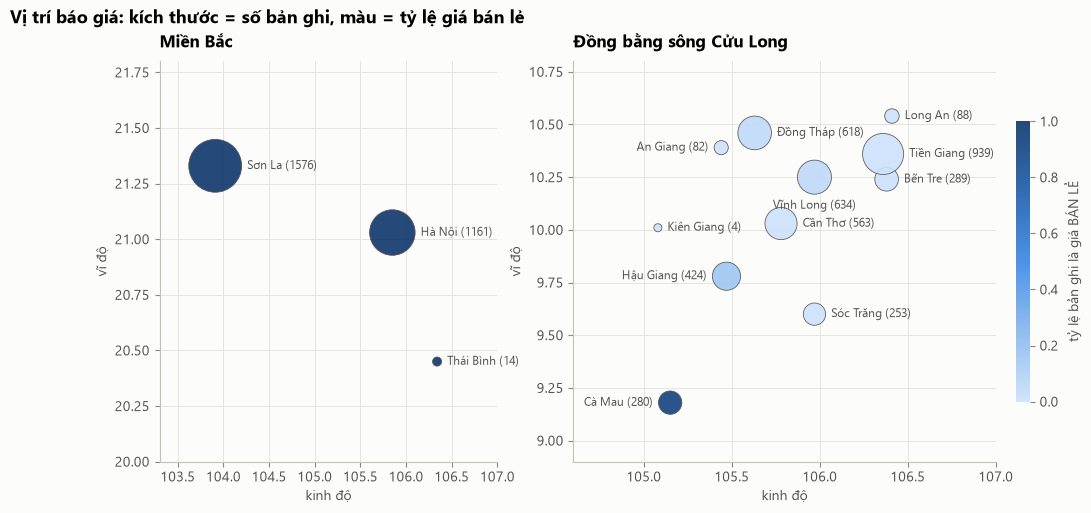

cap_gia,Bán buôn,Bán lẻ,Thu mua
vung,,,
Trung du & miền núi phía Bắc,0,1576,0
Đồng bằng sông Cửu Long,378,385,3411
Đồng bằng sông Hồng,0,1175,0


In [12]:
TOA_DO = {  # (vĩ độ, kinh độ) gần đúng của tỉnh lỵ
    "Hà Nội": (21.03, 105.85), "Sơn La": (21.33, 103.91), "Thái Bình": (20.45, 106.34), "Long An": (10.54, 106.41),
    "Tiền Giang": (10.36, 106.36), "Bến Tre": (10.24, 106.38), "Trà Vinh": (9.95, 106.34),
    "Vĩnh Long": (10.25, 105.97), "Đồng Tháp": (10.46, 105.63), "An Giang": (10.39, 105.44),
    "Cần Thơ": (10.03, 105.78), "Hậu Giang": (9.78, 105.47), "Sóc Trăng": (9.60, 105.97),
    "Kiên Giang": (10.01, 105.08), "Cà Mau": (9.18, 105.15),
}
geo = df.groupby("tinh_cu").agg(so_ban_ghi=("median_price", "size"),
                                ty_le_ban_le=("cap_gia", lambda s: (s == "Bán lẻ").mean()),
                                gia_trung_vi=("median_price", "median"))
geo[["lat", "lon"]] = pd.DataFrame(geo.index.map(TOA_DO).tolist(), index=geo.index)

LABEL_LEFT = {"An Giang", "Hậu Giang", "Cà Mau"}                        # đặt nhãn bên trái / bên dưới để khỏi đè nhau
LABEL_BELOW = {"Vĩnh Long"}
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={"width_ratios": [1, 1.25]})
for ax, region, xlim, ylim in ((axes[0], "Miền Bắc", (103.3, 107.0), (20.0, 21.8)),
                               (axes[1], "Đồng bằng sông Cửu Long", (104.6, 107.0), (8.9, 10.8))):
    g = geo[(geo["lat"] > 15) == (region == "Miền Bắc")]
    sc = ax.scatter(g["lon"], g["lat"], s=g["so_ban_ghi"] * 0.9 + 30, c=g["ty_le_ban_le"], cmap=SEQ, vmin=0, vmax=1,
                    edgecolor=INK2, linewidth=0.6, alpha=0.9)
    for name, rr in g.iterrows():
        r_pt = np.sqrt(rr["so_ban_ghi"] * 0.9 + 30) / 2 + 4               # bán kính bong bóng (point) + khoảng hở
        left, below = name in LABEL_LEFT, name in LABEL_BELOW
        xy_off = (0, -r_pt) if below else (-r_pt if left else r_pt, 0)
        ax.annotate(f"{name} ({int(rr['so_ban_ghi'])})", (rr["lon"], rr["lat"]), xytext=xy_off,
                    textcoords="offset points", ha="center" if below else ("right" if left else "left"),
                    va="top" if below else "center", fontsize=8.5, color=INK2)
    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)
    ax.set_title(region)
    ax.set_xlabel("kinh độ")
    ax.set_ylabel("vĩ độ")
cb = fig.colorbar(sc, ax=axes, shrink=0.7, pad=0.02)
cb.set_label("tỷ lệ bản ghi là giá BÁN LẺ", color=INK2)
cb.outline.set_visible(False)
fig.suptitle("Vị trí báo giá: kích thước = số bản ghi, màu = tỷ lệ giá bán lẻ", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
show(fig, "05_dia_ly")
display(df.pivot_table(index="vung", columns="cap_gia", values="median_price", aggfunc="size", fill_value=0))

**Nhận xét địa lý:** giá **bán lẻ** gần như chỉ được báo ở **miền Bắc** (Hà Nội, Sơn La, Thái Bình), còn giá
**thu mua** chỉ ở **Đồng bằng sông Cửu Long** — vùng sản xuất. Vì vậy *vùng* và *cấp giá* gần như trùng nhau;
khi so sánh giá lẻ với giá thu mua luôn phải nhớ đây là 2 thị trường khác nhau (khác cả chi phí vận chuyển).

### 1.5 Nhận định từ EDA và ảnh hưởng tới tiền xử lý / chọn mô hình
| Nhận định | Ảnh hưởng |
|---|---|
| Giá lệch dương, trải từ ~1.000 đến > 300.000 đ/kg | Huấn luyện trên **log(giá)**; tính sai số trên VNĐ |
| Mức giá phụ thuộc mạnh vào **sản phẩm** và **cấp giá** | Mã hoá one-hot `san_pham`, `cap_gia`, `nhom_san_pham`, `vung` |
| Giá tháng này bám rất sát giá lần trước (Spearman ≈ 0,94) | Tạo đặc trưng từ quá khứ; so sánh với mô hình cơ sở "giữ nguyên giá"; thử cho mô hình học *độ thay đổi* thay vì mức giá |
| ~32% tháng trống trong khoảng hoạt động của các chuỗi | Đặc trưng "giá tháng trước" bị thiếu → điền trung vị + cột đánh dấu thiếu; thêm "số tháng cách" |
| Dữ liệu có thứ tự thời gian | **Chia train/test theo thời gian**, CV theo khối tháng (không xáo trộn) để không rò rỉ |
| Quan hệ phi tuyến, tương tác sản phẩm × mùa vụ | Kỳ vọng mô hình cây (Decision Tree, Random Forest) tốt hơn Linear Regression |
| Nhiều nhóm ít mẫu (loại giá hiếm, tỉnh ít bản ghi) | Dùng `cap_gia` thay `loai_gia`; one-hot bỏ qua giá trị lạ ở tập kiểm tra |

## 2. Tiền xử lý dữ liệu
### 2.1 Tạo đặc trưng
Mọi đặc trưng chỉ dùng thông tin **trước** tháng cần dự đoán (giá lần báo trước, cùng kỳ năm trước…), nên khi dự
đoán tháng *t* ta đã biết chúng → đây là bài toán dự đoán 1 bước, không rò rỉ tương lai.

In [13]:
d = df.copy()
d["log_gia"] = np.log(d["median_price"])
g = d.groupby("sid")
prev_month = g["month"].shift(1)
d["so_thang_cach"] = ((d["month"].dt.year - prev_month.dt.year) * 12 + d["month"].dt.month - prev_month.dt.month)
d["log_gia_lan_truoc"] = g["log_gia"].shift(1)                                    # lần báo giá gần nhất (bất kể cách mấy tháng)
d["log_gia_thang_truoc"] = np.where(d["so_thang_cach"] == 1, d["log_gia_lan_truoc"], np.nan)   # đúng tháng t-1
d["log_tb_3_lan_truoc"] = g["log_gia"].transform(lambda s: s.shift(1).rolling(3, min_periods=1).mean())
d["bien_do_lan_truoc"] = g["max_price"].shift(1) / g["min_price"].shift(1)       # độ phân tán giá trong tháng trước
d["so_lan_bao_gia_truoc"] = g["n_obs"].shift(1)
d["thu_tu_trong_chuoi"] = g.cumcount()                                            # chuỗi đã có bao nhiêu tháng dữ liệu
# giá cùng tháng năm trước (nếu có)
lag12 = d[["sid", "month", "log_gia"]].copy()
lag12["month"] = lag12["month"] + pd.DateOffset(months=12)
d = d.merge(lag12.rename(columns={"log_gia": "log_gia_cung_ky"}), on=["sid", "month"], how="left")
d["thang_sin"] = np.sin(2 * np.pi * d["month_no"] / 12)
d["thang_cos"] = np.cos(2 * np.pi * d["month_no"] / 12)

NUM = ["log_gia_lan_truoc", "log_gia_thang_truoc", "log_tb_3_lan_truoc", "log_gia_cung_ky", "so_thang_cach",
       "bien_do_lan_truoc", "so_lan_bao_gia_truoc", "thu_tu_trong_chuoi", "year", "thang_sin", "thang_cos"]
CAT = ["nhom_san_pham", "san_pham", "cap_gia", "vung"]
TARGET = "median_price"
miss = d[NUM].isna().mean().rename("% thiếu").mul(100).to_frame()
miss["vì sao thiếu"] = ["tháng đầu tiên của chuỗi", "tháng trước trống / tháng đầu", "tháng đầu tiên của chuỗi",
                         "chưa đủ 1 năm / tháng đó năm trước trống", "tháng đầu tiên", "tháng đầu tiên",
                         "tháng đầu tiên", "-", "-", "-", "-"]
miss

,% thiếu,vì sao thiếu
log_gia_lan_truoc,6.195,tháng đầu tiên của chuỗi
log_gia_thang_truoc,12.159,tháng trước trống / tháng đầu
log_tb_3_lan_truoc,6.195,tháng đầu tiên của chuỗi
log_gia_cung_ky,54.859,chưa đủ 1 năm / tháng đó năm trước trống
so_thang_cach,6.195,tháng đầu tiên
bien_do_lan_truoc,6.195,tháng đầu tiên
so_lan_bao_gia_truoc,6.195,tháng đầu tiên
thu_tu_trong_chuoi,0.000,-
year,0.000,-
thang_sin,0.000,-


### 2.2 Chia tập huấn luyện / kiểm tra theo thời gian
- **Huấn luyện:** 04/2021 → 12/2024 · **Kiểm tra:** 01/2025 → 12/2025 (giữ riêng, chỉ dùng một lần ở cuối).
- Không chia ngẫu nhiên như Đề 01: nếu xáo trộn, mô hình được "nhìn thấy" giá của tháng sau khi học tháng trước
  của cùng chuỗi → điểm số ảo.
- **Cross-validation** trên tập huấn luyện: 4 khối thời gian liên tiếp (train trên các tháng trước, kiểm tra
  trên khối tháng kế tiếp) — tương tự `TimeSeriesSplit` nhưng cắt theo ranh giới tháng.

In [14]:
CUT = pd.Timestamp("2025-01-01")
train = d[d["month"] < CUT].reset_index(drop=True)
test = d[d["month"] >= CUT].reset_index(drop=True)
X_train, y_train = train[NUM + CAT], train[TARGET]
X_test, y_test = test[NUM + CAT], test[TARGET]
print(f"Huấn luyện: {len(train):,} bản ghi ({train['month'].min():%m/%Y} → {train['month'].max():%m/%Y})")
print(f"Kiểm tra  : {len(test):,} bản ghi ({test['month'].min():%m/%Y} → {test['month'].max():%m/%Y}) "
      f"— {len(test) / len(d):.0%} dữ liệu")
print(f"Sản phẩm ở tập kiểm tra nhưng không có trong huấn luyện: "
      f"{sorted(set(test['san_pham']) - set(train['san_pham']))}")


def time_folds(months, n_splits=4, min_train_months=12):
    """Các cặp (train_idx, val_idx) theo khối tháng liên tiếp, train luôn nằm trước validation."""
    uniq = np.sort(months.unique())
    blocks = np.array_split(uniq[min_train_months:], n_splits)
    for b in blocks:
        yield np.where(months < b[0])[0], np.where(months.isin(b))[0]


CV = list(time_folds(train["month"]))
for i, (tr, va) in enumerate(CV, 1):
    print(f"  fold {i}: train {len(tr):,} dòng đến {train['month'][tr].max():%m/%Y} | "
          f"validation {len(va):,} dòng {train['month'][va].min():%m/%Y} → {train['month'][va].max():%m/%Y}")

Huấn luyện: 5,005 bản ghi (04/2021 → 12/2024)
Kiểm tra  : 1,920 bản ghi (01/2025 → 12/2025) — 28% dữ liệu
Sản phẩm ở tập kiểm tra nhưng không có trong huấn luyện: ['Cải', 'Dâu tây', 'Măng tây', 'Mận hậu', 'Sapo']
  fold 1: train 987 dòng đến 03/2022 | validation 1,314 dòng 04/2022 → 12/2022
  fold 2: train 2,301 dòng đến 12/2022 | validation 440 dòng 01/2023 → 08/2023
  fold 3: train 2,741 dòng đến 08/2023 | validation 915 dòng 09/2023 → 04/2024
  fold 4: train 3,656 dòng đến 04/2024 | validation 1,349 dòng 05/2024 → 12/2024


### 2.3 Pipeline tiền xử lý
- **Số:** điền giá trị thiếu bằng **trung vị** của tập huấn luyện + thêm **cột đánh dấu thiếu** (thông tin "không
  có giá tháng trước" tự nó có ý nghĩa); **chuẩn hoá z-score** (cần cho Linear Regression; cây không bị ảnh hưởng).
- **Phân loại:** mã hoá **one-hot**, bỏ qua giá trị lạ ở tập kiểm tra.
- Tất cả nằm trong `Pipeline` → mọi tham số tiền xử lý (trung vị, trung bình, độ lệch chuẩn) **chỉ học từ tập huấn
  luyện / fold huấn luyện**, không rò rỉ sang tập kiểm tra.
- Biến mục tiêu được lấy **log** khi học và đổi ngược về VNĐ khi dự đoán (`TransformedTargetRegressor`).

In [15]:
def make_pipeline(model):
    pre = ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                          ("scale", StandardScaler())]), NUM),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT),
    ])
    return TransformedTargetRegressor(regressor=Pipeline([("pre", pre), ("model", model)]),
                                      func=np.log, inverse_func=np.exp)


class DeltaRegressor(BaseEstimator, RegressorMixin):
    """Học ĐỘ THAY ĐỔI log(giá) − log(giá lần báo trước) thay vì mức giá, rồi cộng lại để ra giá.
    Chuỗi chưa có lần báo trước dùng trung vị log giá của tập huấn luyện làm mốc (học trong fit -> không rò rỉ)."""

    def __init__(self, model=None):
        self.model = model

    def _base(self, X):
        return X["log_gia_lan_truoc"].fillna(self.fill_).to_numpy()

    def fit(self, X, y):
        self.fill_ = float(np.median(np.log(y)))
        self.pipe_ = make_pipeline(clone(self.model)).regressor          # cùng tiền xử lý, không lấy log mục tiêu lần nữa
        self.pipe_.fit(X, np.log(np.asarray(y)) - self._base(X))
        return self

    def predict(self, X):
        return np.exp(self._base(X) + self.pipe_.predict(X))


SCORING = {"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"}
make_pipeline(LinearRegression())

,"regressor regressor: object, default=NoneRegressor object such as derived from:class:`~sklearn.base.RegressorMixin`. This regressor willautomatically be cloned each time prior to fitting. If `regressor isNone`, :class:`~sklearn.linear_model.LinearRegression` is created and used.",Pipeline(step...egression())])
,"func func: function, default=NoneFunction to apply to `y` before passing to :meth:`fit`. Cannot be setat the same time as `transformer`. If `func is None`, the function used will bethe identity function. If `func` is set, `inverse_func` also needs to beprovided. The function needs to return a 2-dimensional array.",<ufunc 'log'>
,"inverse_func inverse_func: function, default=NoneFunction to apply to the prediction of the regressor. Cannot be set atthe same time as `transformer`. The inverse function is used to returnpredictions to the same space of the original training labels. If`inverse_func` is set, `func` also needs to be provided. The inversefunction needs to return a 2-dimensional array.",<ufunc 'exp'>
,"transformer transformer: object, default=NoneEstimator object such as derived from:class:`~sklearn.base.TransformerMixin`. Cannot be set at the same timeas `func` and `inverse_func`. If `transformer is None` as well as`func` and `inverse_func`, the transformer will be an identitytransformer. Note that the transformer will be cloned during fitting.Also, the transformer is restricting `y` to be a numpy array.",None
,"check_inverse check_inverse: bool, default=TrueWhether to check that `transform` followed by `inverse_transform`or `func` followed by `inverse_func` leads to the original targets.",True
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('pre', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate 

## 3. Học có giám sát — Dự đoán giá
### 3.1 Mô hình cơ sở
- **Cơ sở 1 — `DummyRegressor` (trung vị):** luôn đoán giá trung vị của tập huấn luyện (mức tối thiểu phải vượt).
- **Cơ sở 2 — "giữ nguyên giá":** đoán giá tháng này = giá lần báo gần nhất. Đây là cách người làm nghề vẫn làm,
  nên là đối chứng **khó** hơn và thực tế hơn.

In [16]:
def scores(y_true, y_pred):
    return {"RMSE": np.sqrt(mean_squared_error(y_true, y_pred)), "MAE": mean_absolute_error(y_true, y_pred),
            "R²": r2_score(y_true, y_pred), "MAPE": np.mean(np.abs(y_pred - y_true) / y_true)}


def cv_naive(data):
    rows = []
    for tr, va in CV:
        v = data.iloc[va]
        fill = np.exp(data.iloc[tr]["log_gia"].median())
        rows.append(scores(v[TARGET], np.exp(v["log_gia_lan_truoc"]).fillna(fill)))
    return pd.DataFrame(rows).mean()


def cv_model(model):
    res = cross_validate(make_pipeline(model), X_train, y_train, cv=CV, scoring=SCORING, n_jobs=-1)
    return pd.Series({"RMSE": -res["test_rmse"].mean(), "MAE": -res["test_mae"].mean(), "R²": res["test_r2"].mean()})


cv_table = pd.DataFrame({
    "Cơ sở: Dummy (trung vị)": cv_model(DummyRegressor(strategy="median")),
    "Cơ sở: giữ nguyên giá": cv_naive(train),
}).T
cv_table[["RMSE", "MAE", "R²"]]

,RMSE,MAE,R²
Cơ sở: Dummy (trung vị),"22,070.883","13,645.560",-0.201
Cơ sở: giữ nguyên giá,"10,910.862","4,194.604",0.714


### 3.2 Linear Regression

In [17]:
cv_table.loc["Linear Regression"] = cv_model(LinearRegression())
cv_table[["RMSE", "MAE", "R²"]]

,RMSE,MAE,R²
Cơ sở: Dummy (trung vị),"22,070.883","13,645.560",-0.201
Cơ sở: giữ nguyên giá,"10,910.862","4,194.604",0.714
Linear Regression,"12,399.529","5,699.330",0.568


### 3.3 Decision Tree — ảnh hưởng của `max_depth` tới underfitting / overfitting
Với mỗi độ sâu, đo RMSE trên phần **huấn luyện** và phần **validation** của 4 fold thời gian.

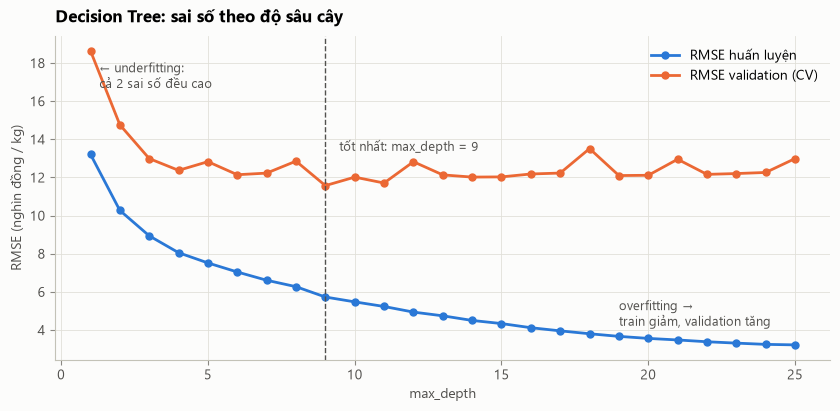

               train  validation
max_depth                       
1         13,214.000  18,639.000
2         10,271.000  14,762.000
4          8,055.000  12,374.000
9          5,731.000  11,574.000
15         4,339.000  12,030.000
25         3,221.000  12,991.000


In [18]:
depths = list(range(1, 26))
curve = []
for depth in depths:
    res = cross_validate(make_pipeline(DecisionTreeRegressor(max_depth=depth, random_state=RANDOM_STATE)),
                         X_train, y_train, cv=CV, scoring="neg_root_mean_squared_error", return_train_score=True,
                         n_jobs=-1)
    curve.append({"max_depth": depth, "train": -res["train_score"].mean(), "validation": -res["test_score"].mean()})
curve = pd.DataFrame(curve).set_index("max_depth")
best_depth = int(curve["validation"].idxmin())

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(curve.index, curve["train"] / 1000, color=S1, marker="o", markersize=5, label="RMSE huấn luyện")
ax.plot(curve.index, curve["validation"] / 1000, color=S2, marker="o", markersize=5, label="RMSE validation (CV)")
ax.axvline(best_depth, color=INK2, linestyle="--", linewidth=1)
ax.annotate(f"tốt nhất: max_depth = {best_depth}", (best_depth, curve["validation"].min() / 1000), xytext=(10, 25),
            textcoords="offset points", color=INK2, fontsize=9)
ax.text(1.3, curve["validation"].max() / 1000 * 0.97, "← underfitting:\ncả 2 sai số đều cao", color=INK2, fontsize=9, va="top")
ax.text(19, curve["train"].iloc[-1] / 1000 + 1.0, "overfitting →\ntrain giảm, validation tăng", color=INK2, fontsize=9)
ax.set_xlabel("max_depth")
ax.set_ylabel("RMSE (nghìn đồng / kg)")
ax.set_title("Decision Tree: sai số theo độ sâu cây")
ax.legend(loc="upper right")
show(fig, "06_decision_tree_max_depth")
print(curve.loc[[1, 2, 4, best_depth, 15, 25]].round(0))

In [19]:
dt_grid = GridSearchCV(make_pipeline(DecisionTreeRegressor(random_state=RANDOM_STATE)),
                       {"regressor__model__max_depth": [best_depth - 2, best_depth - 1, best_depth, best_depth + 1, best_depth + 2],
                        "regressor__model__min_samples_leaf": [1, 5, 10, 20]},
                       cv=CV, scoring="neg_root_mean_squared_error", n_jobs=-1).fit(X_train, y_train)
dt_params = {k.split("__")[-1]: v for k, v in dt_grid.best_params_.items()}
print("Decision Tree — tham số tốt nhất theo CV:", dt_params)
cv_table.loc["Decision Tree"] = cv_model(DecisionTreeRegressor(random_state=RANDOM_STATE, **dt_params))
cv_table[["RMSE", "MAE", "R²"]]

Decision Tree — tham số tốt nhất theo CV: {'max_depth': 9, 'min_samples_leaf': 1}


,RMSE,MAE,R²
Cơ sở: Dummy (trung vị),"22,070.883","13,645.560",-0.201
Cơ sở: giữ nguyên giá,"10,910.862","4,194.604",0.714
Linear Regression,"12,399.529","5,699.330",0.568
Decision Tree,"11,573.652","5,713.708",0.671


### 3.4 Random Forest — chọn tham số bằng GridSearchCV (CV theo thời gian)

In [20]:
rf_grid = GridSearchCV(
    make_pipeline(RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=1)),
    {"regressor__model__n_estimators": [300],
     "regressor__model__max_depth": [10, 20, None],
     "regressor__model__min_samples_leaf": [1, 3, 8],
     "regressor__model__max_features": ["sqrt", 0.5, 1.0]},
    cv=CV, scoring="neg_root_mean_squared_error", n_jobs=-1).fit(X_train, y_train)
rf_params = {k.split("__")[-1]: v for k, v in rf_grid.best_params_.items()}
print("Random Forest — tham số tốt nhất theo CV:", rf_params)
grid_res = pd.DataFrame(rf_grid.cv_results_)
grid_res = grid_res.assign(RMSE=-grid_res["mean_test_score"])[
    ["param_regressor__model__max_depth", "param_regressor__model__min_samples_leaf",
     "param_regressor__model__max_features", "RMSE"]].sort_values("RMSE")
grid_res.columns = ["max_depth", "min_samples_leaf", "max_features", "RMSE CV"]
display(grid_res.head(8))
cv_table.loc["Random Forest"] = cv_model(RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=1, **rf_params))
cv_table[["RMSE", "MAE", "R²"]]

Random Forest — tham số tốt nhất theo CV: {'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 1, 'n_estimators': 300}


,max_depth,min_samples_leaf,max_features,RMSE CV
21,None,1,0.500,"10,982.986"
12,20,1,0.500,"11,059.688"
24,None,1,1.000,"11,223.565"
15,20,1,1.000,"11,241.204"
3,10,1,0.500,"11,312.920"
13,20,3,0.500,"11,363.501"
22,None,3,0.500,"11,395.637"
6,10,1,1.000,"11,422.647"


,RMSE,MAE,R²
Cơ sở: Dummy (trung vị),"22,070.883","13,645.560",-0.201
Cơ sở: giữ nguyên giá,"10,910.862","4,194.604",0.714
Linear Regression,"12,399.529","5,699.330",0.568
Decision Tree,"11,573.652","5,713.708",0.671
Random Forest,"10,982.986","4,923.939",0.714


**Nhận xét:** trên CV, các mô hình học *mức giá* chỉ ngang (Random Forest) hoặc thua (Linear Regression, Decision
Tree) mô hình cơ sở "giữ nguyên giá". Lý do: phần lớn thông tin nằm ở giá lần trước, nhưng cây phải tự "học lại"
quan hệ giá mới ≈ giá cũ bằng các bậc thang rời rạc, nên sai số lớn hơn việc chép thẳng giá cũ.

### 3.5 Cải tiến: học độ thay đổi so với lần báo giá trước
Thay vì học `log(giá)`, cho mô hình học `log(giá) − log(giá lần trước)` (tức % thay đổi), rồi cộng lại vào giá cũ.
Mô hình chỉ còn phải học **khi nào giá lệch khỏi giá cũ và lệch bao nhiêu** (theo mùa, theo sản phẩm, theo biến
động gần đây). Với Linear Regression, đổi mục tiêu kiểu này cho kết quả **y hệt** (giá lần trước đã là một biến
tuyến tính), nên chỉ áp dụng cho Random Forest. Tham số `min_samples_leaf`, `max_features` được chọn lại bằng
CV theo thời gian như các mô hình khác.

In [21]:
def cv_est(est):
    res = cross_validate(est, X_train, y_train, cv=CV, scoring=SCORING, n_jobs=-1)
    return pd.Series({"RMSE": -res["test_rmse"].mean(), "MAE": -res["test_mae"].mean(), "R²": res["test_r2"].mean()})


delta_grid = GridSearchCV(
    DeltaRegressor(RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=1)),
    {"model__min_samples_leaf": [1, 5, 10, 20, 40], "model__max_features": [0.5, 1.0]},
    cv=CV, scoring="neg_root_mean_squared_error", n_jobs=-1).fit(X_train, y_train)
delta_params = {k.split("__")[-1]: v for k, v in delta_grid.best_params_.items()}
print("RF (học độ thay đổi) — tham số tốt nhất theo CV:", delta_params)
leaf_curve = pd.DataFrame(delta_grid.cv_results_)
display(leaf_curve.assign(RMSE=-leaf_curve["mean_test_score"]).pivot(
    index="param_model__min_samples_leaf", columns="param_model__max_features", values="RMSE").round(0))
cv_table.loc["RF (học độ thay đổi)"] = cv_est(
    DeltaRegressor(RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=1, **delta_params)))
ML_MODELS = ["Linear Regression", "Decision Tree", "Random Forest", "RF (học độ thay đổi)"]
best_name = cv_table.loc[ML_MODELS, "RMSE"].idxmin()           # CHỌN MÔ HÌNH THEO CV, không theo tập kiểm tra
print("Mô hình được chọn (RMSE CV nhỏ nhất):", best_name)
cv_table[["RMSE", "MAE", "R²"]].style.format({"RMSE": "{:,.0f}", "MAE": "{:,.0f}", "R²": "{:.3f}"})

RF (học độ thay đổi) — tham số tốt nhất theo CV: {'max_features': 0.5, 'min_samples_leaf': 1}


param_model__max_features,0.500,1.000
param_model__min_samples_leaf,,
1,"10,315.000","10,337.000"
5,"10,646.000","10,723.000"
10,"10,521.000","10,530.000"
20,"10,535.000","10,534.000"
40,"10,587.000","10,590.000"


Mô hình được chọn (RMSE CV nhỏ nhất): RF (học độ thay đổi)


,RMSE,MAE,R²
Cơ sở: Dummy (trung vị),"22,071","13,646",-0.201
Cơ sở: giữ nguyên giá,"10,911","4,195",0.714
Linear Regression,"12,400","5,699",0.568
Decision Tree,"11,574","5,714",0.671
Random Forest,"10,983","4,924",0.714
RF (học độ thay đổi),"10,315","4,721",0.745


### 3.6 Đánh giá trên tập kiểm tra (năm 2025)
Huấn luyện lại mỗi mô hình với tham số đã chọn trên **toàn bộ** tập huấn luyện, rồi đánh giá **một lần** trên 2025.
Mô hình cuối cùng đã được chọn ở bước trên bằng CV; tập kiểm tra chỉ dùng để báo cáo.

In [22]:
final_models = {
    "Cơ sở: Dummy (trung vị)": make_pipeline(DummyRegressor(strategy="median")),
    "Linear Regression": make_pipeline(LinearRegression()),
    "Decision Tree": make_pipeline(DecisionTreeRegressor(random_state=RANDOM_STATE, **dt_params)),
    "Random Forest": make_pipeline(RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1, **rf_params)),
    "RF (học độ thay đổi)": DeltaRegressor(RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE,
                                                                 n_jobs=-1, **delta_params)),
}
fitted, preds = {}, {}
for name, est in final_models.items():
    fitted[name] = est.fit(X_train, y_train)
    preds[name] = fitted[name].predict(X_test)
preds["Cơ sở: giữ nguyên giá"] = np.exp(test["log_gia_lan_truoc"]).fillna(np.exp(train["log_gia"].median())).values
order = ["Cơ sở: Dummy (trung vị)", "Cơ sở: giữ nguyên giá"] + ML_MODELS
test_table = pd.DataFrame({m: scores(y_test, preds[m]) for m in order}).T
test_table.style.format({"RMSE": "{:,.0f}", "MAE": "{:,.0f}", "R²": "{:.3f}", "MAPE": "{:.1%}"})

,RMSE,MAE,R²,MAPE
Cơ sở: Dummy (trung vị),"22,674","13,531",-0.068,71.1%
Cơ sở: giữ nguyên giá,"8,202","3,439",0.860,14.8%
Linear Regression,"8,138","4,158",0.862,18.4%
Decision Tree,"9,600","4,352",0.808,18.6%
Random Forest,"8,264","3,804",0.858,16.4%
RF (học độ thay đổi),"7,669","3,573",0.878,15.7%


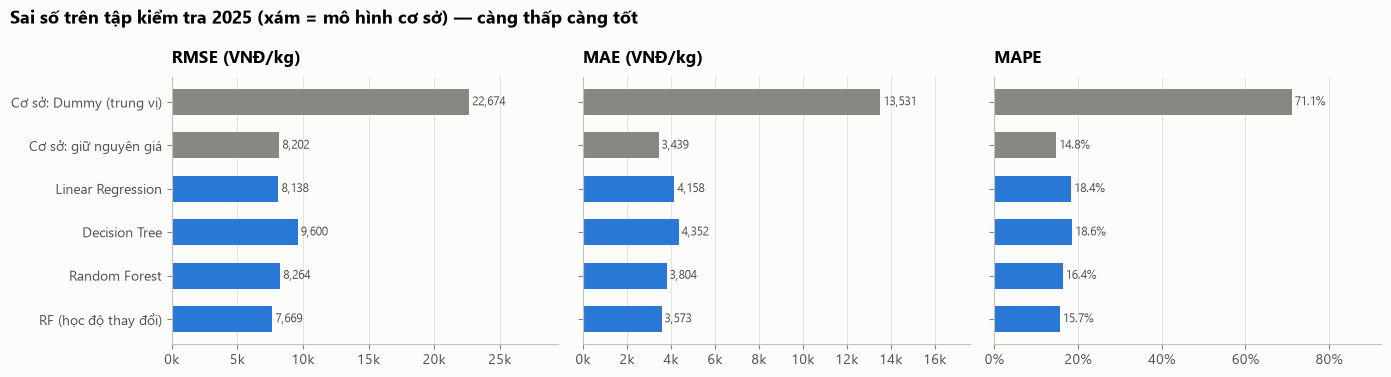

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, metric, fmt in zip(axes, ["RMSE", "MAE", "MAPE"], ["{:,.0f}", "{:,.0f}", "{:.1%}"]):
    vals = test_table.loc[order[::-1], metric]
    colors = [MUTED if m.startswith("Cơ sở") else S1 for m in vals.index]
    bars = ax.barh(vals.index, vals.values, color=colors, height=0.6)
    for b, v in zip(bars, vals.values):
        ax.text(b.get_width(), b.get_y() + b.get_height() / 2, " " + fmt.format(v), va="center", fontsize=8.5, color=INK2)
    ax.set_title(metric + (" (VNĐ/kg)" if metric != "MAPE" else ""))
    ax.grid(axis="y", visible=False)
    ax.set_xlim(0, vals.max() * 1.3)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(
        (lambda v, _: f"{v:.0%}") if metric == "MAPE" else (lambda v, _: f"{v / 1000:g}k")))
fig.suptitle("Sai số trên tập kiểm tra 2025 (xám = mô hình cơ sở) — càng thấp càng tốt", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
fig.tight_layout()
show(fig, "07_so_sanh_test")

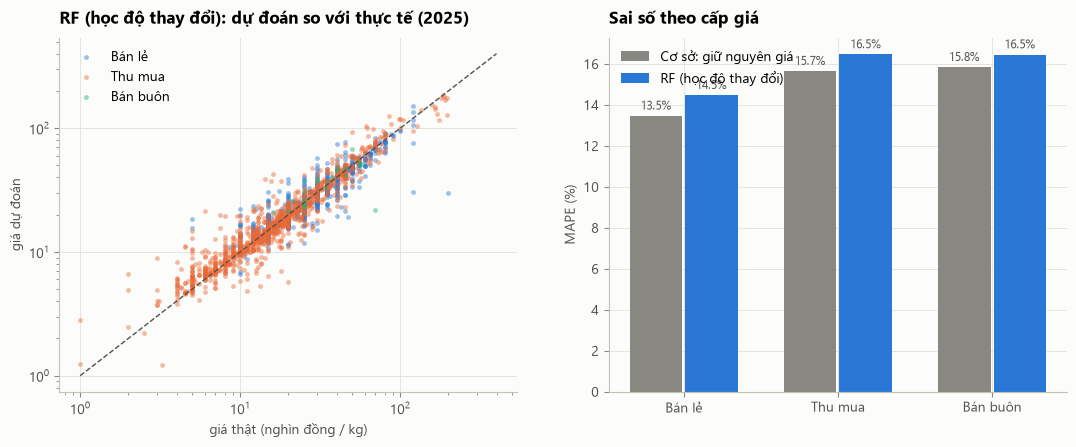

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
ax = axes[0]
for c in CAP_COLOR:
    m = test["cap_gia"] == c
    ax.scatter(y_test[m] / 1000, preds[best_name][m] / 1000, s=12, alpha=0.45, color=CAP_COLOR[c], label=c, linewidth=0)
ax.plot([1, 400], [1, 400], color=INK2, linestyle="--", linewidth=1)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("giá thật (nghìn đồng / kg)")
ax.set_ylabel("giá dự đoán")
ax.set_title(f"{best_name}: dự đoán so với thực tế (2025)")
ax.legend(loc="upper left")
ape = pd.DataFrame({"cap_gia": test["cap_gia"], best_name: np.abs(preds[best_name] - y_test) / y_test,
                    "giữ nguyên giá": np.abs(preds["Cơ sở: giữ nguyên giá"] - y_test) / y_test})
by_cap = ape.groupby("cap_gia")[[best_name, "giữ nguyên giá"]].mean().reindex(list(CAP_COLOR)) * 100
x = np.arange(len(by_cap))
axes[1].bar(x - 0.18, by_cap["giữ nguyên giá"], width=0.34, color=MUTED, label="Cơ sở: giữ nguyên giá")
axes[1].bar(x + 0.18, by_cap[best_name], width=0.34, color=S1, label=best_name)
for i, (a, b) in enumerate(zip(by_cap["giữ nguyên giá"], by_cap[best_name])):
    axes[1].text(i - 0.18, a + 0.3, f"{a:.1f}%", ha="center", fontsize=8.5, color=INK2)
    axes[1].text(i + 0.18, b + 0.3, f"{b:.1f}%", ha="center", fontsize=8.5, color=INK2)
axes[1].set_xticks(x, by_cap.index)
axes[1].set_ylabel("MAPE (%)")
axes[1].set_title("Sai số theo cấp giá")
axes[1].legend(loc="upper left")
show(fig, "08_du_doan_vs_thuc_te")

**Giải thích lựa chọn mô hình cuối cùng: Random Forest học độ thay đổi** (`max_features = 0.5`,
`min_samples_leaf = 1`, 300 cây)
- Được chọn vì có **RMSE cross-validation nhỏ nhất** (≈ 10.300 so với ≈ 10.900 của "giữ nguyên giá"), trước khi
  nhìn tập kiểm tra.
- Trên tập kiểm tra 2025 kết quả được xác nhận: **RMSE thấp nhất** (≈ 7.700, giảm ~6,5% so với "giữ nguyên giá"),
  R² cao nhất (≈ 0,88).
- **Nhưng** MAE và MAPE nhỉnh hơn "giữ nguyên giá" một chút: mô hình giảm được các sai số **lớn** (khi giá biến
  động mạnh theo mùa) nhưng với tháng giá đứng yên thì việc chép giá cũ vẫn khó thắng. Nếu mục tiêu là sai số điển
  hình (MAE) thì "giữ nguyên giá" vẫn là lựa chọn hợp lý; nếu cần tránh các lần đoán trật lớn thì chọn mô hình này.
- Linear Regression có RMSE kiểm tra tốt bất ngờ nhưng RMSE CV kém nhất trong nhóm (≈ 12.400) → không ổn định, không chọn.
- Decision Tree đơn lẻ kém hơn Random Forest ở mọi độ đo — đúng như kỳ vọng: rừng cây trung bình hoá nhiều cây để giảm
  phương sai (overfitting) của một cây.

### 3.7 Tầm quan trọng của các đặc trưng (mô hình được chọn)
- **Impurity importance** của Random Forest (gộp các cột one-hot về đặc trưng gốc).
- **Permutation importance** trên tập kiểm tra: xáo trộn một đặc trưng và đo RMSE tăng bao nhiêu — đáng tin hơn
  vì đo trên dữ liệu chưa thấy và không thiên vị đặc trưng có nhiều giá trị.
- Với mô hình học độ thay đổi, "giá lần trước" vừa là mốc cộng vào vừa là đặc trưng, nên permutation importance
  của nó phản ánh cả hai vai trò.

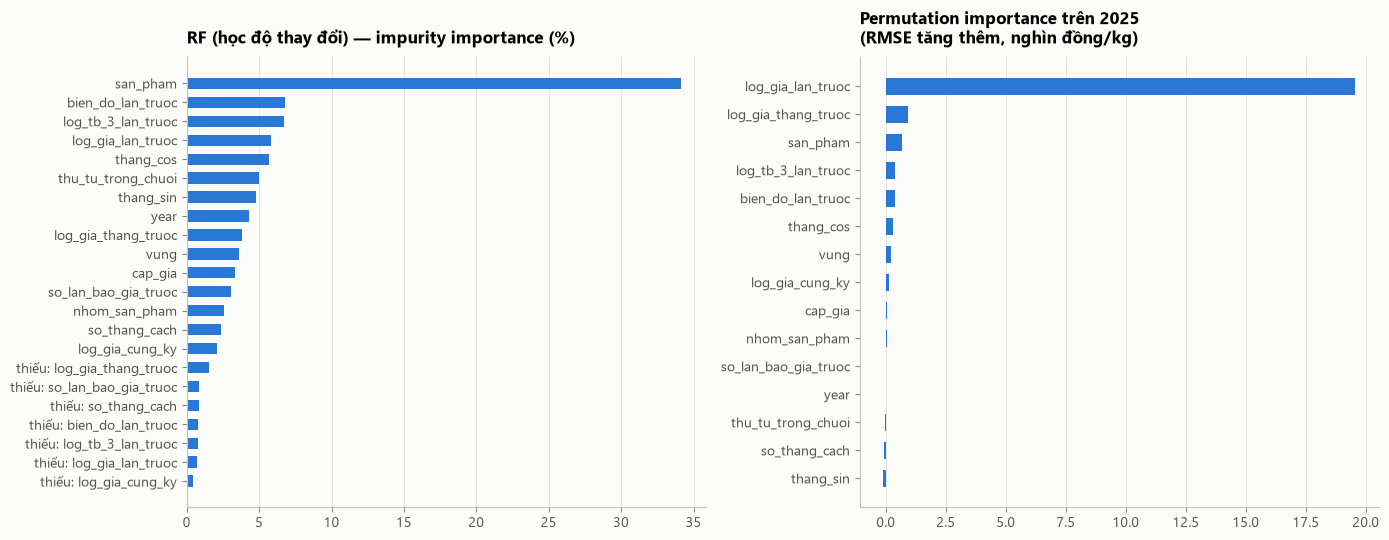

,impurity (%),"permutation (RMSE tăng, VNĐ)"
log_gia_lan_truoc,5.800,"19,560.100"
log_gia_thang_truoc,3.800,912.200
san_pham,34.100,652.900
log_tb_3_lan_truoc,6.700,374.700
bien_do_lan_truoc,6.800,361.000
thang_cos,5.700,299.900
vung,3.600,203.300
log_gia_cung_ky,2.100,151.700
cap_gia,3.300,61.500
nhom_san_pham,2.600,28.200


In [25]:
chosen = fitted[best_name]
rf_pipe = chosen.pipe_ if isinstance(chosen, DeltaRegressor) else chosen.regressor_
names = rf_pipe.named_steps["pre"].get_feature_names_out()
raw_imp = pd.Series(rf_pipe.named_steps["model"].feature_importances_, index=names)


def base_feature(n):
    n = n.split("__", 1)[1]
    if n.startswith("missingindicator_"):
        return "thiếu: " + n.replace("missingindicator_", "")
    for c in CAT:
        if n.startswith(c + "_"):
            return c
    return n


imp_gini = raw_imp.groupby(raw_imp.index.map(base_feature)).sum().sort_values()
perm = permutation_importance(chosen, X_test, y_test, n_repeats=5, random_state=RANDOM_STATE,
                              scoring="neg_root_mean_squared_error", n_jobs=-1)
imp_perm = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
axes[0].barh(imp_gini.index, imp_gini.values * 100, color=S1, height=0.6)
axes[0].set_title(f"{best_name} — impurity importance (%)")
axes[1].barh(imp_perm.index, imp_perm.values / 1000, color=S1, height=0.6)
axes[1].set_title("Permutation importance trên 2025\n(RMSE tăng thêm, nghìn đồng/kg)")
for ax in axes:
    ax.grid(axis="y", visible=False)
fig.tight_layout()
show(fig, "09_tam_quan_trong")
pd.DataFrame({"impurity (%)": imp_gini * 100, "permutation (RMSE tăng, VNĐ)": imp_perm}).sort_values(
    "permutation (RMSE tăng, VNĐ)", ascending=False).round(1)

## 4. Học không giám sát — Phân cụm chuỗi giá
### 4.1 Đặc trưng hành vi của mỗi chuỗi (không dùng mức giá)
Mỗi điểm là **một chuỗi giá** (mặt hàng × tỉnh × loại giá) có ≥ 24 tháng dữ liệu. Giống Đề 01 không dùng giá nhà khi
phân cụm, ở đây **không dùng mức giá**, chỉ dùng *cách giá biến đổi*:

| Đặc trưng | Ý nghĩa |
|---|---|
| `bien_do_mua_vu` | chênh lệch giữa tháng đắt nhất và rẻ nhất trong năm (sau khi trừ xu hướng từng năm) |
| `thang_dinh_sin`, `thang_dinh_cos` | tháng đắt nhất, mã hoá vòng tròn (T12 gần T1) |
| `do_bien_dong` | độ lệch chuẩn của % thay đổi giá giữa 2 tháng liên tiếp |
| `xu_huong_nam` | tốc độ tăng/giảm giá trung bình mỗi năm |
| `ty_le_dung_gia` | tỷ lệ tháng giá gần như không đổi (±2%) |

In [26]:
d["year_"] = d["month"].dt.year
ycnt = d.groupby(["sid", "year_"])["log_gia"].transform("size")
dd = d[ycnt >= 6].copy()
dd["dev"] = dd["log_gia"] - dd.groupby(["sid", "year_"])["log_gia"].transform("mean")
prof = dd.groupby(["sid", "month_no"])["dev"].mean().unstack()

feat_rows = []
for sid, gg in d.groupby("sid"):
    if len(gg) < 24 or sid not in prof.index or prof.loc[sid].notna().sum() < 10:
        continue
    p = prof.loc[sid]
    consec = gg["so_thang_cach"] == 1
    r = (gg["log_gia"] - gg["log_gia_lan_truoc"])[consec]
    t_years = (gg["month"] - gg["month"].min()).dt.days / 365.25
    peak = int(p.idxmax())
    feat_rows.append({
        "sid": sid,
        "bien_do_mua_vu": np.expm1(p.max()) - np.expm1(p.min()),
        "thang_dinh_sin": np.sin(2 * np.pi * peak / 12), "thang_dinh_cos": np.cos(2 * np.pi * peak / 12),
        "do_bien_dong": r.std(),
        "xu_huong_nam": np.expm1(np.polyfit(t_years, gg["log_gia"], 1)[0]),
        "ty_le_dung_gia": (r.abs() <= np.log1p(0.02)).mean(),
        "thang_dinh": peak,
    })
F = pd.DataFrame(feat_rows).set_index("sid")
meta = d.drop_duplicates("sid").set_index("sid")[["nhom_san_pham", "san_pham", "mat_hang", "tinh_cu", "vung", "cap_gia"]]
F = F.join(meta)
F["gia_trung_vi"] = d.groupby("sid")["median_price"].median()
FEATS = ["bien_do_mua_vu", "thang_dinh_sin", "thang_dinh_cos", "do_bien_dong", "xu_huong_nam", "ty_le_dung_gia"]
print(f"{len(F)} chuỗi đủ điều kiện (≥ 24 tháng, ≥ 10/12 tháng trong năm có số liệu)")
F[FEATS].describe().T

122 chuỗi đủ điều kiện (≥ 24 tháng, ≥ 10/12 tháng trong năm có số liệu)


,count,mean,std,min,25%,50%,75%,max
bien_do_mua_vu,122.000,0.441,0.259,0.032,0.235,0.393,0.622,1.216
thang_dinh_sin,122.000,0.059,0.726,-1.000,-0.775,-0.000,0.866,1.000
thang_dinh_cos,122.000,0.068,0.687,-1.000,-0.500,-0.000,0.866,1.000
do_bien_dong,122.000,0.192,0.100,0.024,0.116,0.171,0.257,0.555
xu_huong_nam,122.000,0.014,0.138,-0.389,-0.043,0.035,0.087,0.576
ty_le_dung_gia,122.000,0.369,0.197,0.000,0.218,0.362,0.483,0.938


Chuẩn hoá **z-score** trước khi phân cụm: K-Means và DBSCAN dựa trên khoảng cách Euclid nên bắt buộc đưa các
đặc trưng về cùng thang đo (Bài 6, Bài 10).

In [27]:
Xc = StandardScaler().fit_transform(F[FEATS])

### 4.2 K-Means — chọn K bằng Elbow và Silhouette

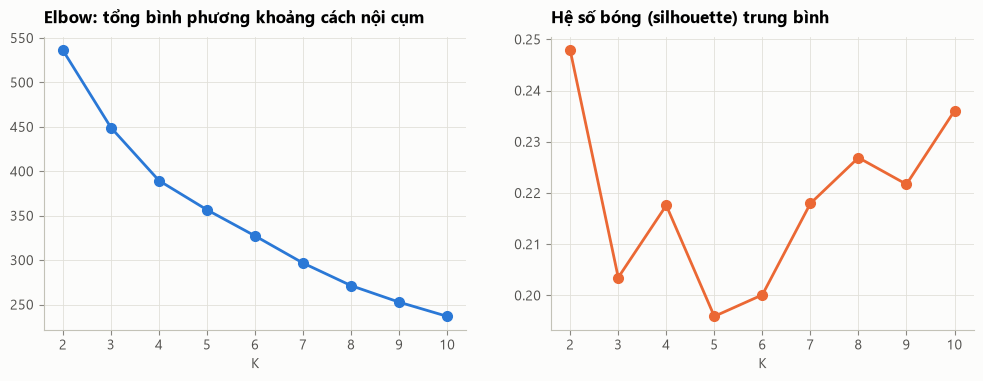

K,2,3,4,5,6,7,8,9,10
inertia,536.099,449.122,389.467,356.567,327.226,296.641,271.258,252.661,236.702
silhouette,0.248,0.203,0.218,0.196,0.200,0.218,0.227,0.222,0.236


In [28]:
ks = range(2, 11)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=30, random_state=RANDOM_STATE).fit(Xc)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(Xc, km.labels_))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(list(ks), inertia, color=S1, marker="o", markersize=7)
axes[0].set_title("Elbow: tổng bình phương khoảng cách nội cụm")
axes[0].set_xlabel("K")
axes[1].plot(list(ks), sil, color=S2, marker="o", markersize=7)
axes[1].set_title("Hệ số bóng (silhouette) trung bình")
axes[1].set_xlabel("K")
show(fig, "10_chon_k")
pd.DataFrame({"K": list(ks), "inertia": inertia, "silhouette": sil}).set_index("K").T.round(3)

**Chọn K = 4**
- **Elbow:** tổng bình phương nội cụm giảm 16% từ K = 2 → 3, 13% từ 3 → 4, rồi chỉ còn 8% từ 4 → 5 → đường cong
  bắt đầu "gãy" quanh K = 4.
- **Silhouette:** K = 2 cao nhất (0,25) nhưng chỉ tách "ổn định / biến động" — quá thô cho mục đích phân khúc;
  K = 4 là đỉnh cục bộ (0,22, cao hơn K = 3 và K = 5).
- **Diễn giải được:** 4 cụm ứng với 4 nhịp giá có ý nghĩa nghiệp vụ (mục 4.3).
- **Lưu ý trung thực:** silhouette mọi K chỉ khoảng 0,2 → theo Bài 11 đây là **cấu trúc cụm yếu**, các cụm chồng lấn
  nhau; nên đọc kết quả như *xu hướng* chứ không phải các nhóm tách bạch.

In [29]:
K = 4
km = KMeans(n_clusters=K, n_init=30, random_state=RANDOM_STATE).fit(Xc)
F["cum_kmeans"] = km.labels_
centers = F.groupby("cum_kmeans")[FEATS[:1] + FEATS[3:] + ["thang_dinh"]].agg(
    {"bien_do_mua_vu": "mean", "do_bien_dong": "mean", "xu_huong_nam": "mean", "ty_le_dung_gia": "mean",
     "thang_dinh": lambda s: s.mode().iloc[0]})
centers["số chuỗi"] = F["cum_kmeans"].value_counts()
centers["silhouette cụm"] = pd.Series(silhouette_samples(Xc, km.labels_)).groupby(km.labels_).mean()
centers.style.format({"bien_do_mua_vu": "{:.0%}", "do_bien_dong": "{:.3f}", "xu_huong_nam": "{:+.1%}",
                      "ty_le_dung_gia": "{:.0%}", "silhouette cụm": "{:.2f}"})

,bien_do_mua_vu,do_bien_dong,xu_huong_nam,ty_le_dung_gia,thang_dinh,số chuỗi,silhouette cụm
cum_kmeans,,,,,,,
0,25%,0.124,+0.9%,45%,9,33,0.23
1,89%,0.360,-12.4%,17%,1,17,0.19
2,39%,0.178,+3.0%,34%,4,34,0.23
3,45%,0.188,+6.6%,42%,12,38,0.21


### 4.3 Mô tả, đặt tên cụm và đối chiếu với giá, vùng, cấp giá

In [30]:
def name_cluster(c):
    """Đặt tên từ tâm cụm, so với phân vị của toàn bộ chuỗi."""
    if c["bien_do_mua_vu"] < F["bien_do_mua_vu"].quantile(0.35) and c["do_bien_dong"] < F["do_bien_dong"].quantile(0.35):
        return "Ổn định, ít mùa vụ"
    if c["do_bien_dong"] > F["do_bien_dong"].quantile(0.75):
        trend = ", giá đi xuống" if c["xu_huong_nam"] < -0.05 else ""
        return f"Biến động mạnh, mùa vụ sâu{trend}"
    trend = ", giá tăng dần" if c["xu_huong_nam"] > 0.05 else ""
    return f"Mùa vụ vừa, đỉnh T{int(c['thang_dinh'])}{trend}"


names = {i: f"Cụm {i}: {name_cluster(centers.loc[i])}" for i in centers.index}
F["ten_cum"] = F["cum_kmeans"].map(names)
for i in centers.index:
    sub = F[F["cum_kmeans"] == i]
    print(f"\n{names[i]} — {len(sub)} chuỗi")
    print("  sản phẩm tiêu biểu:", ", ".join(sub["san_pham"].value_counts().index[:8]))
    print("  cấp giá:", sub["cap_gia"].value_counts().to_dict(), "| vùng:", sub["vung"].value_counts().to_dict())


Cụm 0: Ổn định, ít mùa vụ — 33 chuỗi
  sản phẩm tiêu biểu: Bưởi, Nhãn, Khoai tây, Cà rốt, Ổi, Chuối, Cam, Bí đỏ
  cấp giá: {'Thu mua': 17, 'Bán lẻ': 15, 'Bán buôn': 1} | vùng: {'Đồng bằng sông Cửu Long': 21, 'Đồng bằng sông Hồng': 6, 'Trung du & miền núi phía Bắc': 6}

Cụm 1: Biến động mạnh, mùa vụ sâu, giá đi xuống — 17 chuỗi
  sản phẩm tiêu biểu: Xoài, Thanh long, Cam, Nhãn, Sầu riêng, Rau ngót, Bắp cải, Mít
  cấp giá: {'Thu mua': 15, 'Bán lẻ': 2} | vùng: {'Đồng bằng sông Cửu Long': 15, 'Trung du & miền núi phía Bắc': 2}

Cụm 2: Mùa vụ vừa, đỉnh T4 — 34 chuỗi
  sản phẩm tiêu biểu: Cam, Chanh, Xoài, Quả bí, Mướp, Quýt, Thanh long, Nhãn
  cấp giá: {'Thu mua': 22, 'Bán lẻ': 11, 'Bán buôn': 1} | vùng: {'Đồng bằng sông Cửu Long': 23, 'Trung du & miền núi phía Bắc': 9, 'Đồng bằng sông Hồng': 2}

Cụm 3: Mùa vụ vừa, đỉnh T12, giá tăng dần — 38 chuỗi
  sản phẩm tiêu biểu: Dưa hấu, Xoài, Cà chua, Khổ qua, Bắp cải, Bầu, Dưa leo, Dứa
  cấp giá: {'Thu mua': 19, 'Bán lẻ': 19} | vùng: {'Đồng bằng 

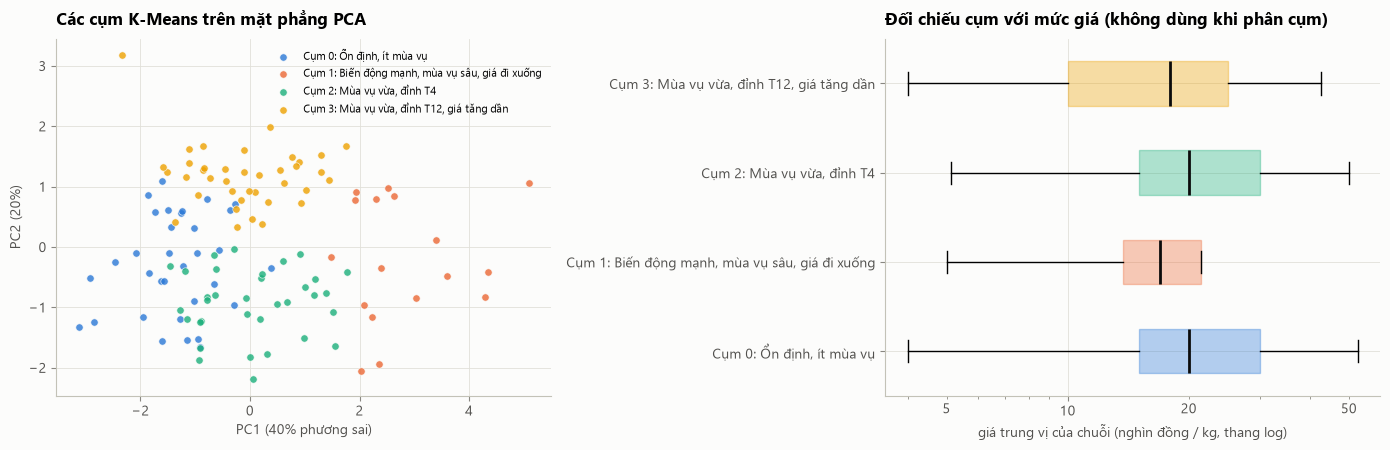

cap_gia,Bán buôn,Bán lẻ,Thu mua,tổng
ten_cum,,,,
"Cụm 0: Ổn định, ít mùa vụ",1,15,17,33
"Cụm 1: Biến động mạnh, mùa vụ sâu, giá đi xuống",0,2,15,17
"Cụm 2: Mùa vụ vừa, đỉnh T4",1,11,22,34
"Cụm 3: Mùa vụ vừa, đỉnh T12, giá tăng dần",0,19,19,38
tổng,2,47,73,122


vung,Trung du & miền núi phía Bắc,Đồng bằng sông Cửu Long,Đồng bằng sông Hồng
ten_cum,,,
"Cụm 0: Ổn định, ít mùa vụ",6,21,6
"Cụm 1: Biến động mạnh, mùa vụ sâu, giá đi xuống",2,15,0
"Cụm 2: Mùa vụ vừa, đỉnh T4",9,23,2
"Cụm 3: Mùa vụ vừa, đỉnh T12, giá tăng dần",8,24,6


In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(Xc)
P = pca.transform(Xc)
colors = [S1, S2, S3, S4]
for i in range(K):
    m = F["cum_kmeans"].values == i
    axes[0].scatter(P[m, 0], P[m, 1], s=28, color=colors[i], alpha=0.8, label=names[i], edgecolor=SURF, linewidth=0.5)
axes[0].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} phương sai)")
axes[0].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
axes[0].set_title("Các cụm K-Means trên mặt phẳng PCA")
axes[0].legend(fontsize=8, loc="best")
data = [F.loc[F["cum_kmeans"] == i, "gia_trung_vi"] / 1000 for i in range(K)]
bp = axes[1].boxplot(data, vert=False, tick_labels=[names[i] for i in range(K)], patch_artist=True, widths=0.5,
                     showfliers=False, medianprops=dict(color=INK, linewidth=2))
for p_, c in zip(bp["boxes"], colors):
    p_.set(facecolor=c, alpha=0.35, edgecolor=c)
axes[1].set_xscale("log")
plain_log_x(axes[1])
axes[1].set_xlabel("giá trung vị của chuỗi (nghìn đồng / kg, thang log)")
axes[1].set_title("Đối chiếu cụm với mức giá (không dùng khi phân cụm)")
fig.tight_layout()
show(fig, "11_cum_kmeans")
display(pd.crosstab(F["ten_cum"], F["cap_gia"], margins=True, margins_name="tổng"))
display(pd.crosstab(F["ten_cum"], F["vung"]))

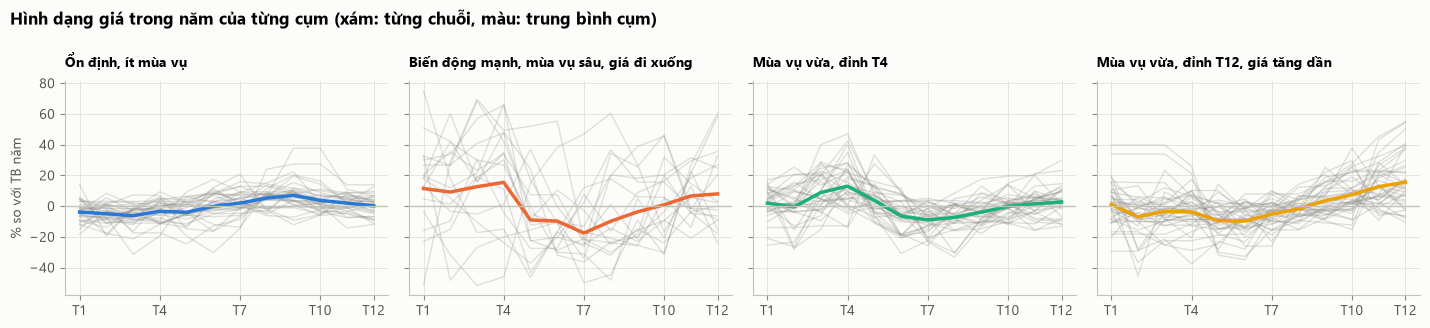

In [32]:
# Hình dạng mùa vụ trung bình của từng cụm
fig, axes = plt.subplots(1, K, figsize=(3.6 * K, 3.3), sharey=True)
for ax, i in zip(axes, range(K)):
    sids = F.index[F["cum_kmeans"] == i]
    for sid in sids:
        ax.plot(range(1, 13), np.expm1(prof.loc[sid].values) * 100, color=MUTED, alpha=0.25, linewidth=1)
    ax.plot(range(1, 13), np.expm1(prof.loc[sids].mean().values) * 100, color=colors[i], linewidth=2.5)
    ax.axhline(0, color=AXIS, linewidth=1)
    ax.set_title(names[i].split(": ", 1)[1], fontsize=10)
    ax.set_xticks([1, 4, 7, 10, 12], ["T1", "T4", "T7", "T10", "T12"])
axes[0].set_ylabel("% so với TB năm")
fig.suptitle("Hình dạng giá trong năm của từng cụm (xám: từng chuỗi, màu: trung bình cụm)", x=0.01, ha="left",
             fontsize=12.5, fontweight="bold")
fig.tight_layout()
show(fig, "12_hinh_dang_cum")

### 4.4 DBSCAN — tìm nhóm dày đặc và chuỗi dị biệt
**Vì sao không chạy DBSCAN trên toạ độ như Đề 01:** dữ liệu chỉ có 15 tỉnh (15 toạ độ khác nhau), nên DBSCAN theo địa
lý không có gì để tìm. Thay vào đó chạy DBSCAN trên **cùng 6 đặc trưng hành vi** đã chuẩn hoá: các điểm DBSCAN gán
nhãn **nhiễu (−1)** là những chuỗi có hành vi giá khác hẳn phần còn lại — dị biệt theo mật độ (Bài 11, Bài 13).

**Chọn tham số**
- `min_samples` = số chiều + 1 = 7 (quy tắc kinh nghiệm: ít nhất D + 1 điểm mới gọi là vùng dày đặc).
- `eps`: vẽ **đồ thị k-khoảng cách** (khoảng cách tới láng giềng thứ `min_samples` của mỗi điểm, sắp tăng dần) và chọn
  tại **điểm gãy** — sau điểm đó khoảng cách tăng vọt, tức là các điểm đã nằm ở vùng thưa.

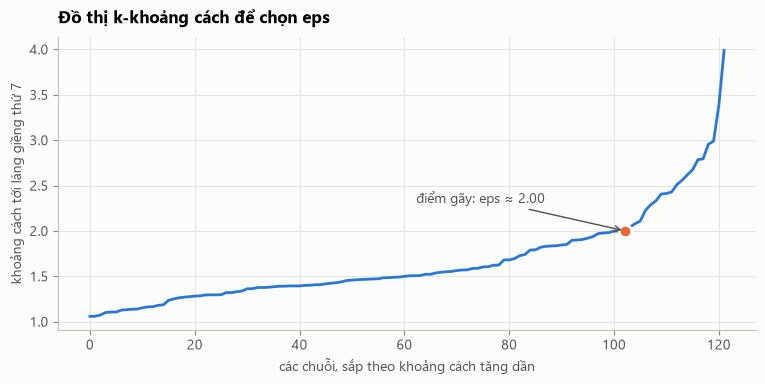

DBSCAN (eps=2.00, min_samples=7): 1 cụm, 6 điểm nhiễu (5%), 102 điểm lõi, 14 điểm biên


ten_cum,"Cụm 0: Ổn định, ít mùa vụ","Cụm 1: Biến động mạnh, mùa vụ sâu, giá đi xuống","Cụm 2: Mùa vụ vừa, đỉnh T4","Cụm 3: Mùa vụ vừa, đỉnh T12, giá tăng dần"
cum_dbscan,,,,
cụm 0,33,12,34,37
nhiễu (−1),0,5,0,1


In [33]:
MIN_SAMPLES = len(FEATS) + 1
nn = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(Xc)
kdist = np.sort(nn.kneighbors(Xc)[0][:, -1])
# điểm gãy = điểm xa nhất so với đường thẳng nối đầu và cuối đồ thị
xs = np.arange(len(kdist))
x1, y1, x2, y2 = 0, kdist[0], len(kdist) - 1, kdist[-1]
dist_line = np.abs((y2 - y1) * xs - (x2 - x1) * kdist + x2 * y1 - y2 * x1) / np.hypot(y2 - y1, x2 - x1)
knee = int(np.argmax(dist_line))
EPS = float(kdist[knee])

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(xs, kdist, color=S1)
ax.scatter([knee], [EPS], s=80, color=S2, zorder=3, edgecolor=SURF, linewidth=2)
ax.annotate(f"điểm gãy: eps ≈ {EPS:.2f}", (knee, EPS), xytext=(-150, 20), textcoords="offset points", color=INK2,
            arrowprops=dict(arrowstyle="->", color=INK2))
ax.set_xlabel("các chuỗi, sắp theo khoảng cách tăng dần")
ax.set_ylabel(f"khoảng cách tới láng giềng thứ {MIN_SAMPLES}")
ax.set_title("Đồ thị k-khoảng cách để chọn eps")
show(fig, "13_k_distance")

db = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit(Xc)
F["cum_dbscan"] = db.labels_
n_clusters = len(set(db.labels_)) - (1 if -1 in db.labels_ else 0)
noise = (db.labels_ == -1).sum()
core = np.zeros(len(Xc), bool)
core[db.core_sample_indices_] = True
print(f"DBSCAN (eps={EPS:.2f}, min_samples={MIN_SAMPLES}): {n_clusters} cụm, {noise} điểm nhiễu ({noise / len(F):.0%}), "
      f"{core.sum()} điểm lõi, {len(F) - core.sum() - noise} điểm biên")
if n_clusters >= 2:
    m = db.labels_ != -1
    print(f"Silhouette (bỏ điểm nhiễu): {silhouette_score(Xc[m], db.labels_[m]):.3f}")
display(pd.crosstab(F["cum_dbscan"].map(lambda v: "nhiễu (−1)" if v == -1 else f"cụm {v}"), F["ten_cum"]))

**Kết quả:** với `eps` tại điểm gãy, DBSCAN gom gần như mọi chuỗi vào **một** vùng dày đặc và tách riêng một số ít
chuỗi làm **nhiễu**. Điều này khớp với silhouette thấp của K-Means: dữ liệu *không có* các nhóm tách rời nhau về mật
độ, chỉ có một "đám" chính và vài điểm lạc. Giảm `eps` (bảng dưới) thì sinh thêm cụm nhỏ nhưng số điểm nhiễu tăng
vọt — dấu hiệu các cụm đó không ổn định. Vì vậy DBSCAN ở đây có giá trị như **bộ phát hiện chuỗi dị biệt**.

In [34]:
# Độ nhạy theo eps: số cụm và số điểm nhiễu
sens = []
for e in np.round(np.linspace(EPS * 0.6, EPS * 1.6, 11), 2):
    lab = DBSCAN(eps=e, min_samples=MIN_SAMPLES).fit_predict(Xc)
    sens.append({"eps": e, "số cụm": len(set(lab)) - (1 if -1 in lab else 0), "số điểm nhiễu": int((lab == -1).sum())})
display(pd.DataFrame(sens).set_index("eps").T)

eps,1.200,1.400,1.600,1.800,2.000,2.200,2.400,2.600,2.800,3.000,3.200
số cụm,2,4,1,1,1,1,1,1,1,1,1
số điểm nhiễu,79,37,22,16,6,5,3,3,2,2,1


In [35]:
outliers = F[F["cum_dbscan"] == -1].copy()
z = pd.DataFrame(Xc, index=F.index, columns=FEATS).loc[outliers.index]
outliers["đặc trưng lệch nhất"] = z.abs().idxmax(axis=1) + " (z = " + z.abs().max(axis=1).round(1).astype(str) + ")"
cols = ["san_pham", "mat_hang", "tinh_cu", "cap_gia", "bien_do_mua_vu", "do_bien_dong", "xu_huong_nam",
        "ty_le_dung_gia", "đặc trưng lệch nhất"]
outliers.sort_values("do_bien_dong", ascending=False)[cols].head(12).style.format(
    {"bien_do_mua_vu": "{:.0%}", "do_bien_dong": "{:.3f}", "xu_huong_nam": "{:+.0%}", "ty_le_dung_gia": "{:.0%}"})

,san_pham,mat_hang,tinh_cu,cap_gia,bien_do_mua_vu,do_bien_dong,xu_huong_nam,ty_le_dung_gia,đặc trưng lệch nhất
sid,,,,,,,,,
409,Xoài,Xoài Đài Loan,Đồng Tháp,Thu mua,122%,0.555,-2%,0%,do_bien_dong (z = 3.6)
212,Cóc Thái,Cóc Thái,Đồng Tháp,Thu mua,112%,0.513,-17%,33%,do_bien_dong (z = 3.2)
340,Sầu riêng,Sầu Riêng Ri 6 (loại xô),Cần Thơ,Thu mua,78%,0.338,-37%,39%,xu_huong_nam (z = 2.8)
319,Nhãn,Nhãn tiêu da bò,Đồng Tháp,Thu mua,67%,0.275,-39%,27%,xu_huong_nam (z = 2.9)
401,Xoài,Xoài cát Hòa Lộc,Đồng Tháp,Thu mua,74%,0.275,-3%,3%,ty_le_dung_gia (z = 1.7)
193,Chanh leo,Chanh leo tím,Sơn La,Bán lẻ,52%,0.118,+58%,85%,xu_huong_nam (z = 4.1)


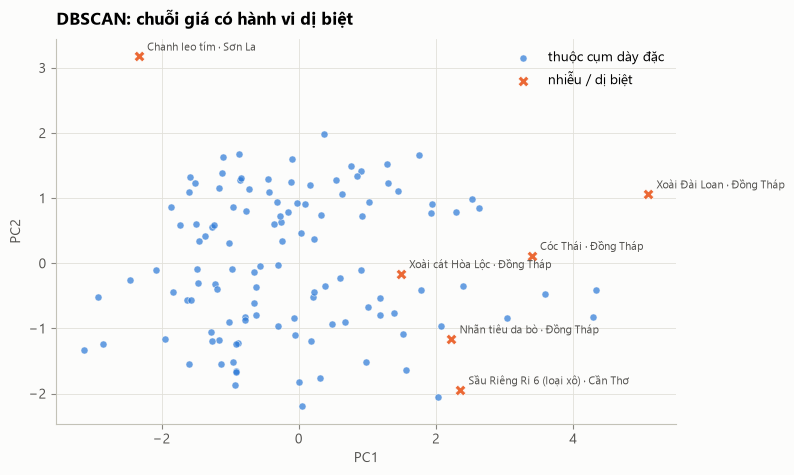

In [36]:
fig, ax = plt.subplots(figsize=(8, 5))
m = F["cum_dbscan"].values == -1
ax.scatter(P[~m, 0], P[~m, 1], s=26, color=S1, alpha=0.7, label="thuộc cụm dày đặc", edgecolor=SURF, linewidth=0.5)
ax.scatter(P[m, 0], P[m, 1], s=60, color=S2, marker="X", label="nhiễu / dị biệt", edgecolor=SURF, linewidth=0.5)
for sid in outliers.sort_values("do_bien_dong", ascending=False).index[:6]:
    i = F.index.get_loc(sid)
    ax.annotate(f"{F.loc[sid, 'mat_hang']} · {F.loc[sid, 'tinh_cu']}", (P[i, 0], P[i, 1]), xytext=(6, 4),
                textcoords="offset points", fontsize=8, color=INK2)
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("DBSCAN: chuỗi giá có hành vi dị biệt")
ax.legend(loc="best")
show(fig, "14_dbscan")

### 4.5 So sánh K-Means và DBSCAN
| Tiêu chí | K-Means | DBSCAN |
|---|---|---|
| Cần biết trước số cụm | Có (chọn K bằng Elbow + Silhouette) | Không — số cụm tự sinh từ `eps`, `min_samples` |
| Hình dạng cụm | Cầu, kích thước gần nhau | Bất kỳ, theo mật độ |
| Điểm dị biệt | Bị ép vào cụm gần nhất, kéo lệch tâm cụm | Tách riêng thành nhiễu (−1) |
| Độ nhạy tham số | Nhạy với khởi tạo (dùng `n_init` = 30) | Rất nhạy với `eps` (bảng độ nhạy ở trên) |
| Kết quả trên dữ liệu này | Chia toàn bộ chuỗi thành K nhóm diễn giải được | Phần lớn chuỗi dồn vào ít cụm lớn, tách ra một số chuỗi dị biệt |
| **Phù hợp cho** | **Phân khúc mặt hàng theo nhịp giá** (lập kế hoạch thu mua, dự trữ theo mùa) | **Phát hiện chuỗi giá bất thường** cần kiểm tra lại với nguồn |

## 5. Kết luận
### 5.1 Kết quả chính
**Nhiệm vụ 1 — dự đoán giá (hồi quy)**
- Mô hình cơ sở Dummy sai rất xa (MAPE ~71%, R² < 0): chỉ biết sản phẩm và cấp giá là chưa đủ, cần thông tin giá gần đây.
- Mô hình cơ sở **"giữ nguyên giá" rất mạnh** (R² ≈ 0,86 trên 2025): giá rau quả theo tháng có quán tính lớn.
  Linear Regression, Decision Tree và Random Forest học *mức giá* đều **không thắng** được nó.
- **Đổi bài toán sang dự đoán độ thay đổi** giúp Random Forest vượt mô hình cơ sở về RMSE (~6,5%) và R² (0,878 so
  với 0,860) — cải thiện chủ yếu ở các tháng giá biến động mạnh. Đây là bài học quan trọng: **cách đặt biến mục tiêu
  quan trọng hơn việc đổi thuật toán**.
- Decision Tree minh hoạ rõ đánh đổi độ sâu: `max_depth` = 1–2 underfit (RMSE validation 15–19 nghìn), `max_depth`
  = 9 tốt nhất (≈ 11,6 nghìn), sâu hơn thì RMSE huấn luyện tiếp tục giảm còn validation không giảm nữa → overfit.
- Đặc trưng quan trọng nhất: **giá lần báo trước**, sau đó là sản phẩm, trung bình 3 lần gần nhất, độ phân tán giá
  tháng trước và tháng trong năm (mùa vụ).

**Nhiệm vụ 2 — phân cụm chuỗi giá**
- K-Means (K = 4) chia 122 chuỗi thành: *ổn định – ít mùa vụ* (bưởi, khoai tây, cà rốt…), *biến động mạnh – mùa vụ
  sâu – giá thu mua đi xuống* (xoài, thanh long, sầu riêng, nhãn — gần như toàn bộ là giá thu mua ở ĐBSCL), *mùa vụ
  vừa – đỉnh tháng 4* (cam, chanh, quýt), *mùa vụ vừa – đỉnh tháng 12 – giá tăng dần* (cà chua, khổ qua, bắp cải,
  dưa hấu — rau đắt nhất dịp cận Tết).
- Mức giá **không** khác nhiều giữa các cụm → cụm phản ánh *nhịp giá*, không phải *đắt / rẻ*.
- Silhouette ≈ 0,22 → cấu trúc cụm yếu, cụm chồng lấn; DBSCAN xác nhận điều đó (chỉ 1 vùng dày đặc + 6 chuỗi dị biệt,
  phần lớn là giá thu mua trái cây biến động cực mạnh như xoài Đài Loan, cóc Thái ở Đồng Tháp).
- **K-Means hợp với phân khúc** mặt hàng theo nhịp giá (lập kế hoạch thu mua / dự trữ); **DBSCAN hợp với phát hiện
  chuỗi bất thường** cần kiểm tra lại với nguồn.

### 5.2 Hạn chế
- Dữ liệu ngắn và thưa: chuỗi trung bình 16 tháng, ~32% tháng trống; chỉ 122 chuỗi đủ dài để phân cụm.
- Giá bán lẻ chỉ có ở miền Bắc, giá thu mua chỉ ở miền Tây → không tách được ảnh hưởng của *vùng* và *cấp giá*.
- Giá do cộng tác viên báo, hay làm tròn (52% là bội số 5.000đ), có tháng chỉ 1 lần báo giá → nhiễu đo lường cao.
- Chỉ có biến nội tại (lịch sử giá); thiếu các yếu tố gây biến động thật (thời tiết, mùa vụ thu hoạch, xuất khẩu,
  giá xăng, lễ Tết âm lịch).
- Bài toán là dự đoán 1 bước (biết giá tháng trước); nguồn công bố chậm nhiều tháng nên muốn dùng thật cần dự báo xa hơn.

### 5.3 Hướng cải tiến
- Bổ sung dữ liệu ngoài làm đặc trưng: lịch Tết âm lịch, thời tiết theo tỉnh, sản lượng / xuất khẩu (mục 7, 9 cùng cổng
  thông tin), giá xăng dầu; và dữ liệu giá siêu thị Winmart khi đã tích luỹ đủ vài tháng.
- Thử các mô hình boosting (LightGBM / XGBoost) và dự báo nhiều bước kèm khoảng tin cậy.
- Phân cụm theo hình dạng chuỗi bằng khoảng cách DTW, hoặc phân cụm phân cấp (Bài 11) để xem cây gộp cụm.
- Đưa kết quả vào kho: bảng dự báo và nhãn cụm trong ClickHouse để trình diễn trên Superset cùng các khối OLAP.

**Tóm tắt số liệu (tính tự động từ các ô phía trên):**

In [37]:
best_row = test_table.loc[best_name]
naive_row = test_table.loc["Cơ sở: giữ nguyên giá"]
dummy_row = test_table.loc["Cơ sở: Dummy (trung vị)"]
summary = pd.Series({
    "Dữ liệu": f"{len(d):,} bản ghi VNĐ/kg, {d['sid'].nunique()} chuỗi, 04/2021 → 12/2025",
    "Mô hình được chọn (theo RMSE cross-validation)": best_name,
    "RF học độ thay đổi": ", ".join(f"{k} = {v}" for k, v in delta_params.items()),
    "RMSE / MAE / R² mô hình tốt nhất": f"{best_row['RMSE']:,.0f} / {best_row['MAE']:,.0f} / {best_row['R²']:.3f}",
    "RMSE / MAE / R² giữ nguyên giá": f"{naive_row['RMSE']:,.0f} / {naive_row['MAE']:,.0f} / {naive_row['R²']:.3f}",
    "RMSE / MAE / R² Dummy": f"{dummy_row['RMSE']:,.0f} / {dummy_row['MAE']:,.0f} / {dummy_row['R²']:.3f}",
    "Decision Tree": f"max_depth tốt nhất theo CV = {dt_params['max_depth']}, min_samples_leaf = {dt_params['min_samples_leaf']}",
    "Random Forest": ", ".join(f"{k} = {v}" for k, v in rf_params.items()),
    "Đặc trưng quan trọng nhất (permutation)": ", ".join(imp_perm.sort_values(ascending=False).index[:3]),
    "K-Means": f"K = {K}, silhouette = {silhouette_score(Xc, km.labels_):.3f}",
    "DBSCAN": f"eps = {EPS:.2f}, min_samples = {MIN_SAMPLES}: {n_clusters} cụm, {noise} chuỗi dị biệt",
})
summary.to_frame("kết quả")

,kết quả
Dữ liệu,"6,925 bản ghi VNĐ/kg, 429 chuỗi, 04/2021 → 12/..."
Mô hình được chọn (theo RMSE cross-validation),RF (học độ thay đổi)
RF học độ thay đổi,"max_features = 0.5, min_samples_leaf = 1"
RMSE / MAE / R² mô hình tốt nhất,"7,669 / 3,573 / 0.878"
RMSE / MAE / R² giữ nguyên giá,"8,202 / 3,439 / 0.860"
RMSE / MAE / R² Dummy,"22,674 / 13,531 / -0.068"
Decision Tree,"max_depth tốt nhất theo CV = 9, min_samples_le..."
Random Forest,"max_depth = None, max_features = 0.5, min_samp..."
Đặc trưng quan trọng nhất (permutation),"log_gia_lan_truoc, log_gia_thang_truoc, san_pham"
K-Means,"K = 4, silhouette = 0.218"
